Assume that the middle region (am) is solely dependent on (h-d0)/(h-d1), (h-d2)/(h-d1), (h-d1)/radwidth, and radwidth/(a[1]), if the other regions exhibit good convergence.

1. Test this hypothesis by fixing these ratios and varying other values a lot (while maintaining good region i0, i2, e convergence). Plot a histogram of the 1% convergence point for each ordered quad of these ratios and see that their variation is low.
2. If it holds, for a configuration with as many fixed values as possible, each (or a pair of) ratios, find informative ways to plot them, and try to find a function from their values to the convergence point.

In [12]:
import sys
from pathlib import Path
HERE = Path.cwd().resolve()
up2_path = str((HERE / ".." / "..").resolve())
up3_path = str((HERE / ".." / ".." / "..").resolve())
for pathstr in [up2_path, up3_path]:
  if pathstr not in sys.path:
      sys.path.insert(0, pathstr)

from helpers import *
import numpy as np
from numpy import random

import matplotlib.pyplot as plt

file1 = str((HERE / "data" / "histogram-2.pkl").resolve()) # Generates
file2 = str((HERE / "data" / "predetermined-2.pkl").resolve()) # Generates

In [2]:
# Data generation helpers

def random_m0(h):
  # want m0 * h < 30 if expecting some values near 1 for (h-d2)/h
  return random.uniform(low=0.0, high=(30/h))

def populate_hist_vals(h, left_ratio, right_ratio, hmdr, rad_ratio):
  hmd1 = random.uniform(low = 1., high = ((h-1)/1.2))
  hmd0 = left_ratio * hmd1
  hmd2 = right_ratio * hmd1
  radwidth1 = hmd1/hmdr
  radwidth0 = radwidth1/rad_ratio - radwidth1
  radwidth2 = hmd2/random.uniform(low = 1., high = 3.)
  hmds = [hmd0, hmd1, hmd2]
  radwidths = [radwidth0, radwidth1, radwidth2]
  d = [h - hmds[i] for i in range(3)]
  a = [sum(radwidths[:i + 1]) for i in range(3)]
  return d, a

def swap_vals(prob, d, a):
  # Avoids mk recomputations.
  prob.d = d
  prob.a = a
  prob.scale = a
  return prob

In [3]:
# raw data generation / data loading and convergence metrics (file1)

quads = [(0.9, 0.2, 10, 0.3), (0.9, 0.99, 10, 0.3), (0.9, 1.2, 10, 0.3),
         (0.99, 0.2, 20, 0.1), (0.99, 0.99, 20, 0.1), (0.99, 1.2, 20, 0.1),
         (0.5, 0.2, 20, 0.2), (0.5, 0.99, 20, 0.2), (0.5, 1.2, 20, 0.2),
         (0.95, 0.2, 2, 0.6), (0.95, 0.99, 2, 0.6), (0.95, 1.2, 2, 0.6)]

big_nmk = 200
nmk_max = 150
NMK = [big_nmk] * 4
heaving = [0, 1, 0]
rho = 1023

# fixed_prob_lsts = []

# for quad in quads:
#   fixed_prob_lst = []
#   for j in range(50):
#     h = random.uniform(low = 10., high = 50.)
#     m0 = random_m0(h)
#     d, a = populate_hist_vals(h, quad[0], quad[1], quad[2], quad[3])
#     prob = ConvergenceProblemI(h, d, a, heaving, NMK, m0, rho)
#     mk = prob.m_k
#     info = {"h" : h,
#             "d" : d,
#             "a" : a,
#             "region" : 1,
#             "m0s" : [m0]}
#     print(j, info)
#     data_dict = merge_dicts(info, prob.convergence_study_over_m0s(nmk_max, [m0], [mk]))
#     fixed_prob_lst.append(data_dict)
#   fixed_prob_lsts.append(fixed_prob_lst)
#   update_data_file(fixed_prob_lsts, file1)
#   print("Finished a quad.")

fixed_prob_lsts = open_pkl_file(file1)
for fixed_prob_lst in fixed_prob_lsts:
  generate_convergence_data(fixed_prob_lst, [0.01])
  generate_log_data(fixed_prob_lst)

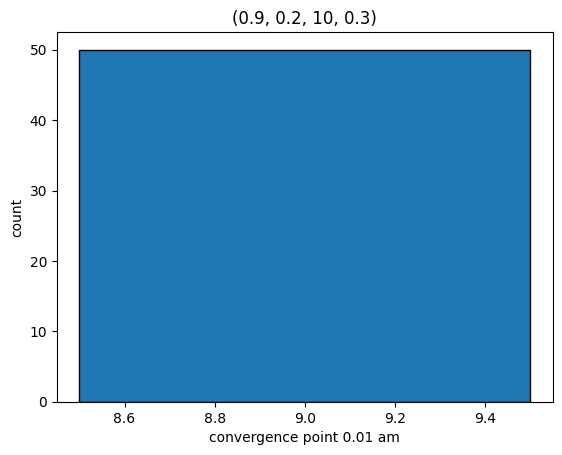

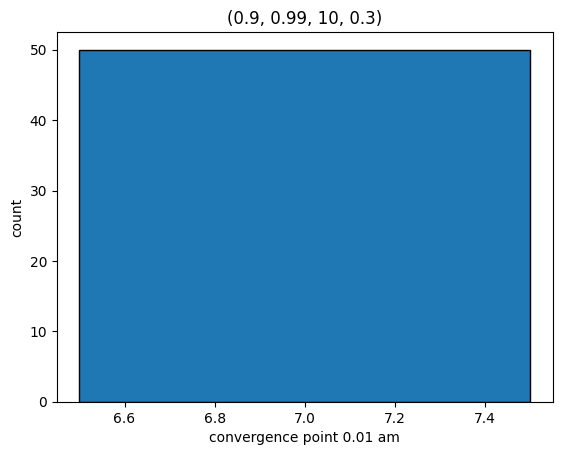

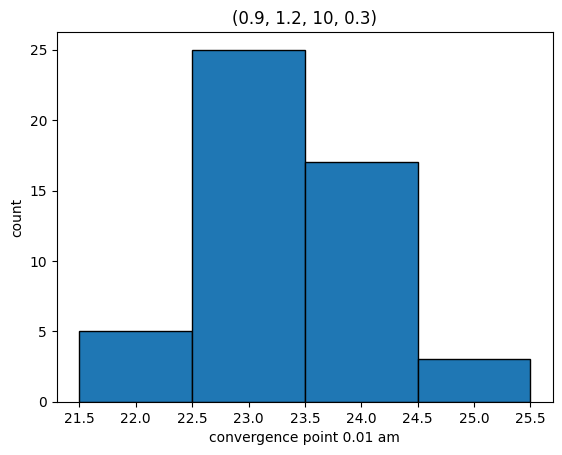

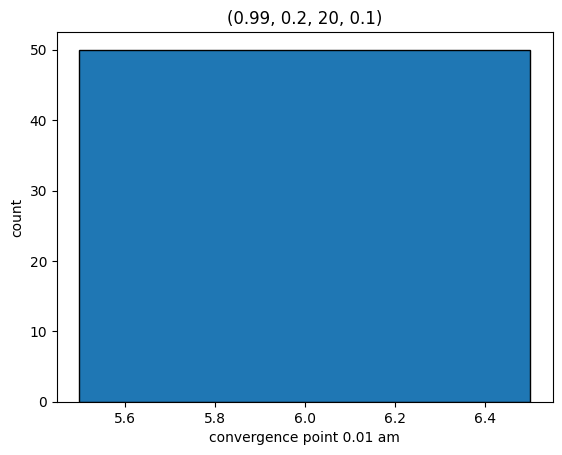

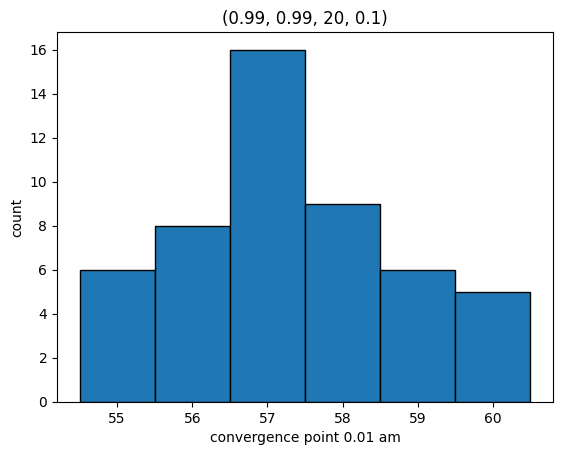

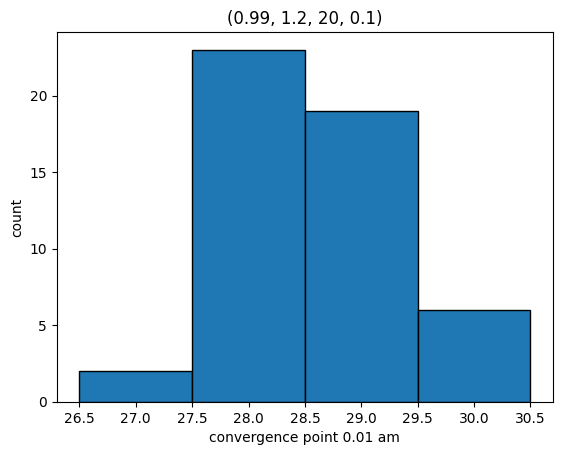

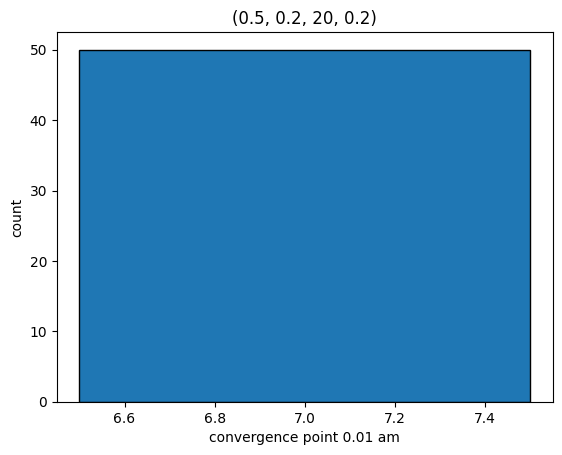

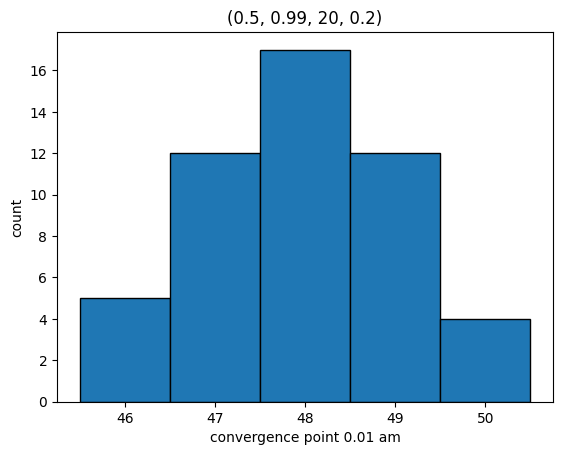

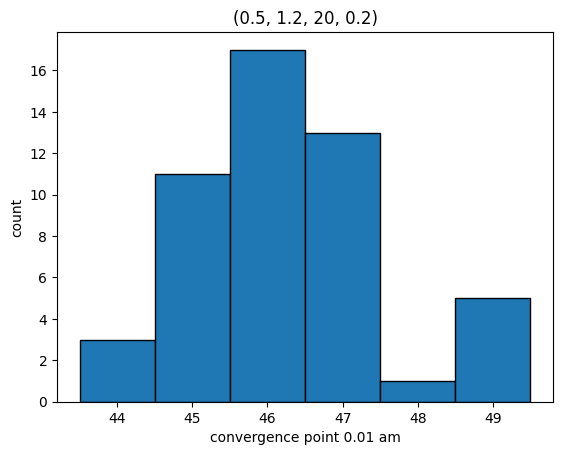

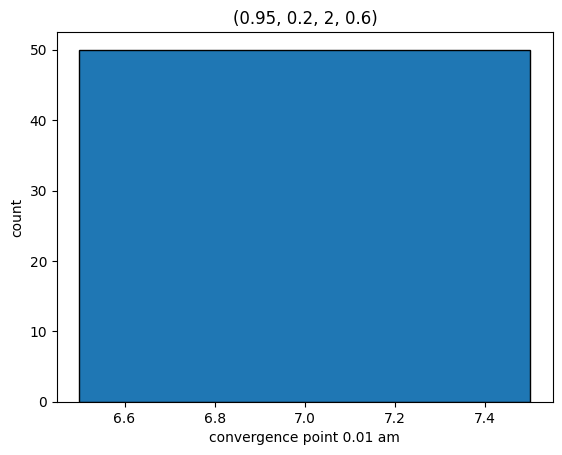

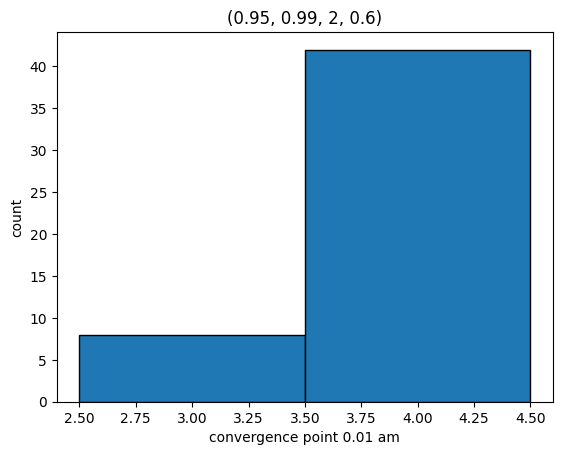

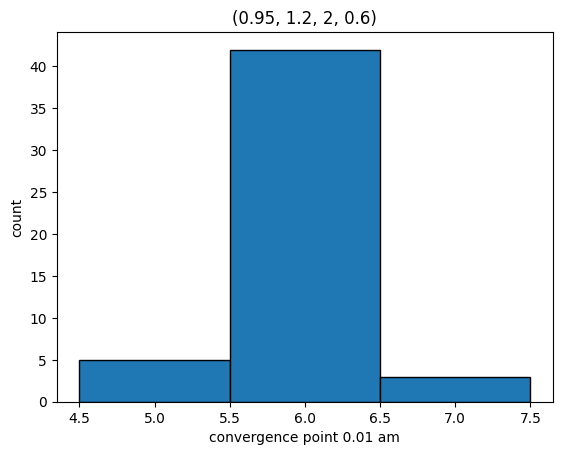

In [4]:
# Appears that all significant variation for added mass is accounted for.
for idx, quad in enumerate(quads):
  vals = histogram(fixed_prob_lsts[idx],"am", 0.01, ylab = "count", title = f"{quad}")

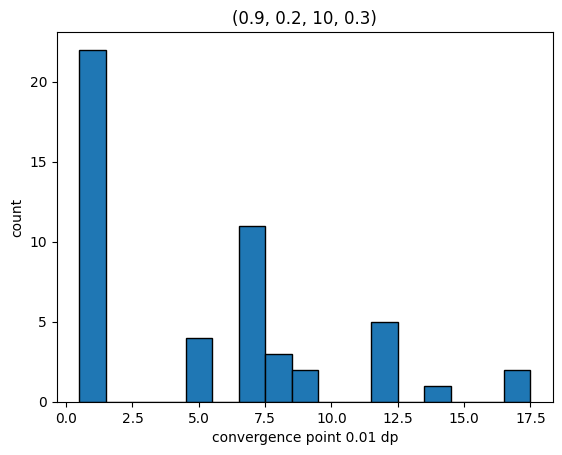

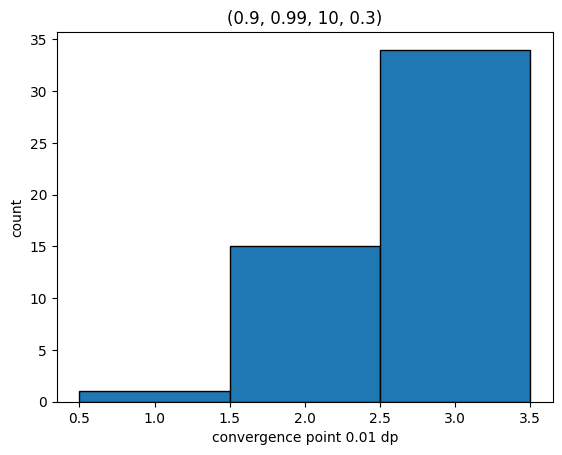

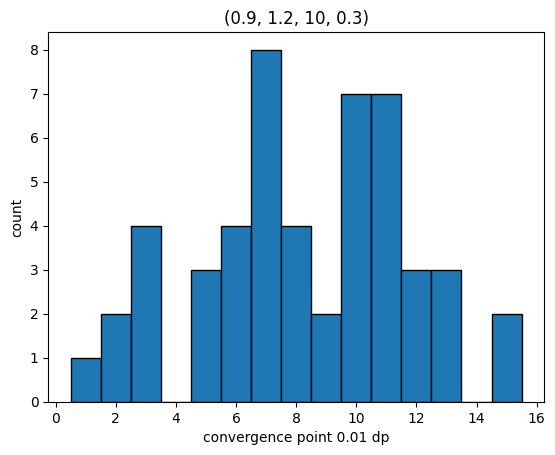

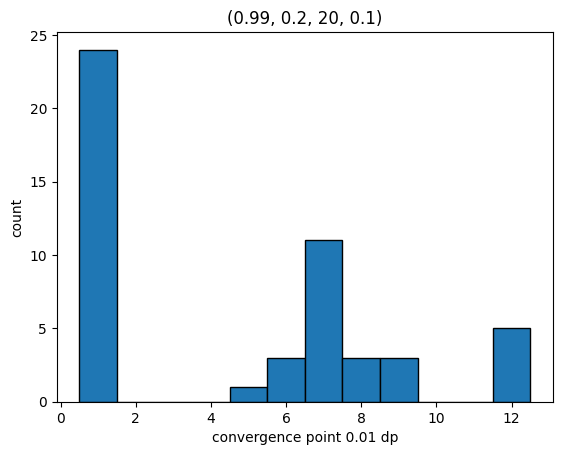

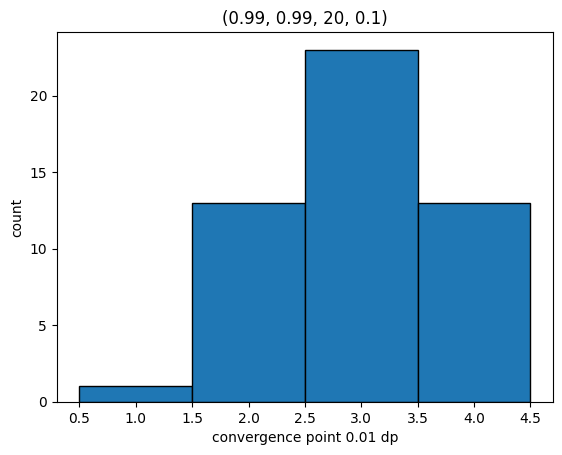

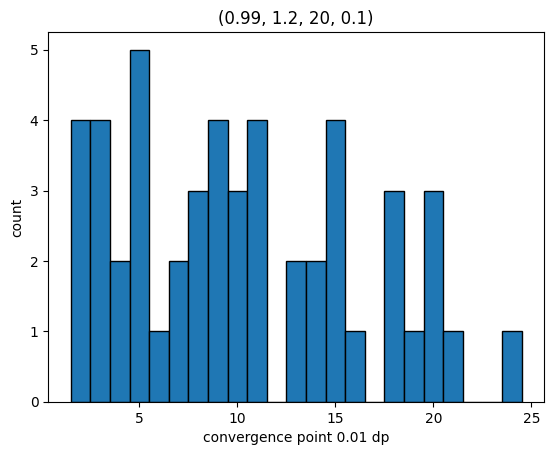

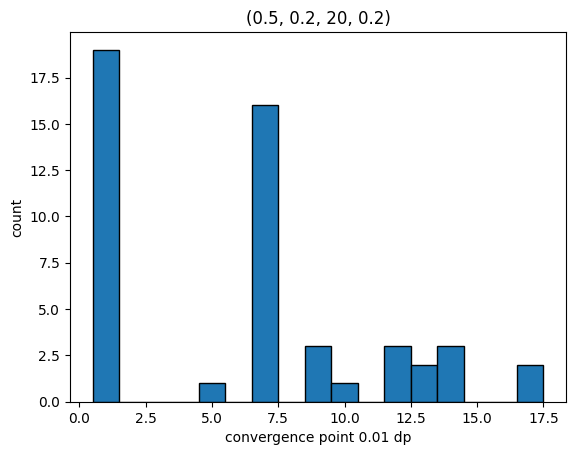

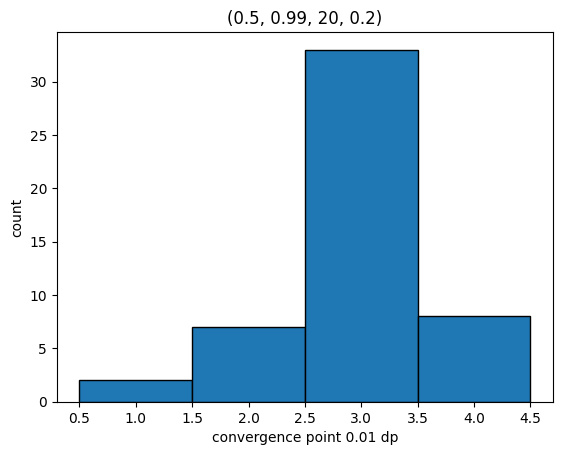

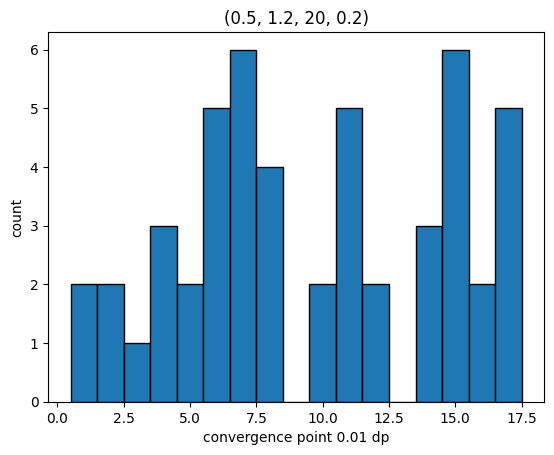

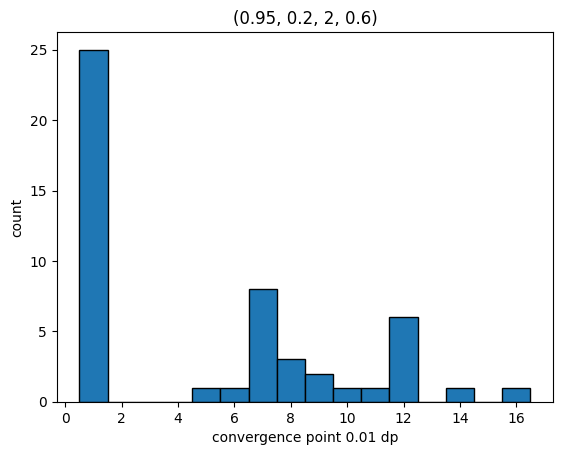

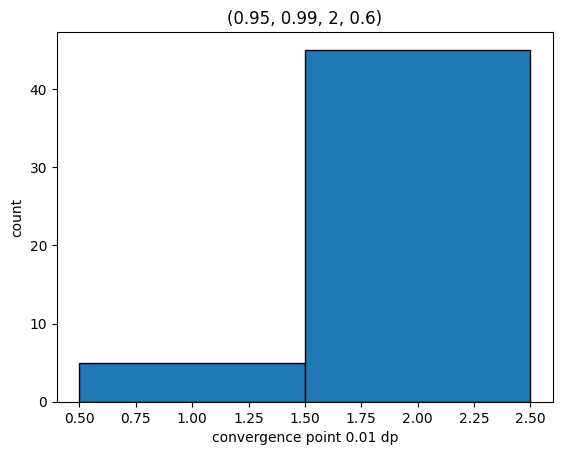

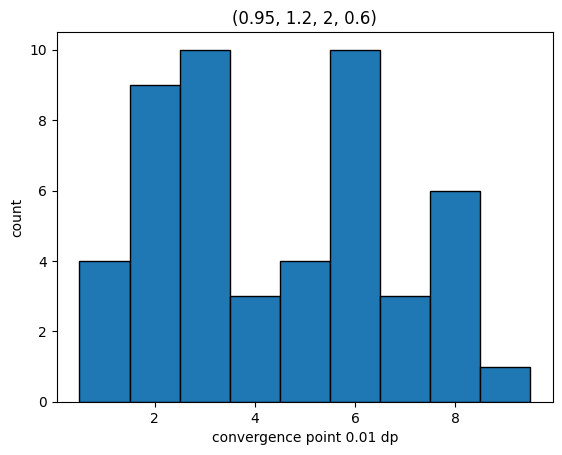

In [5]:
# Unaccounted for significant damping variation remains.
dp_wide_variation_cases = []
for idx, quad in enumerate(quads):
  vals = histogram(fixed_prob_lsts[idx],"dp", 0.01, ylab = "count", title = f"{quad}")
  if max(vals) - min(vals) > 7:
    dp_wide_variation_cases.append(idx)

Try to identified the remaining unaccounted for variance in damping.

In [6]:
# Generate a dicionary of possible ratios.
def hmdi(data_dict, i):
  return data_dict["h"] - data_dict["d"][i]

def di(data_dict, i):
  return data_dict["d"][i]

def radwidthi(data_dict, i):
  return data_dict["a"][i] - (0 if i == 0 else data_dict["a"][i-1])

def radrange(data_dict, i, j):
  return sum([radwidthi(data_dict, k) for k in range(i+1, j + 1)])

dim1s = {"h" : lambda data_dict, m0: data_dict["h"],
        "(1/m0)" : lambda data_dict, m0: 1/m0}

for i in range(3):
  dim1s["d" + str(i)] = lambda data_dict, m0, i=i : di(data_dict, i)
  dim1s["(h-d" + str(i) + ")"] = lambda data_dict, m0, i=i: hmdi(data_dict, i)
  dim1s["radwidth" + str(i)] = lambda data_dict, m0, i=i: radwidthi(data_dict, i)
  for j in range(i + 1, 3):
    dim1s["(a" + str(j) + "-a" + str(i) + ")"] = lambda data_dict, m0, i=i, j=j : radrange(data_dict, i, j)

dim0s = {} # size = 14**2
for key1 in dim1s.keys():
  for key2 in dim1s.keys():
    if key1 == key2:
      pass
    else:
      dim0s[key1 + "/" + key2] = (lambda data_dict, m0, k1 = key1, k2 = key2 : dim1s[k1](data_dict, m0)/dim1s[k2](data_dict, m0))

In [7]:
suspects = fixed_prob_lsts[5]

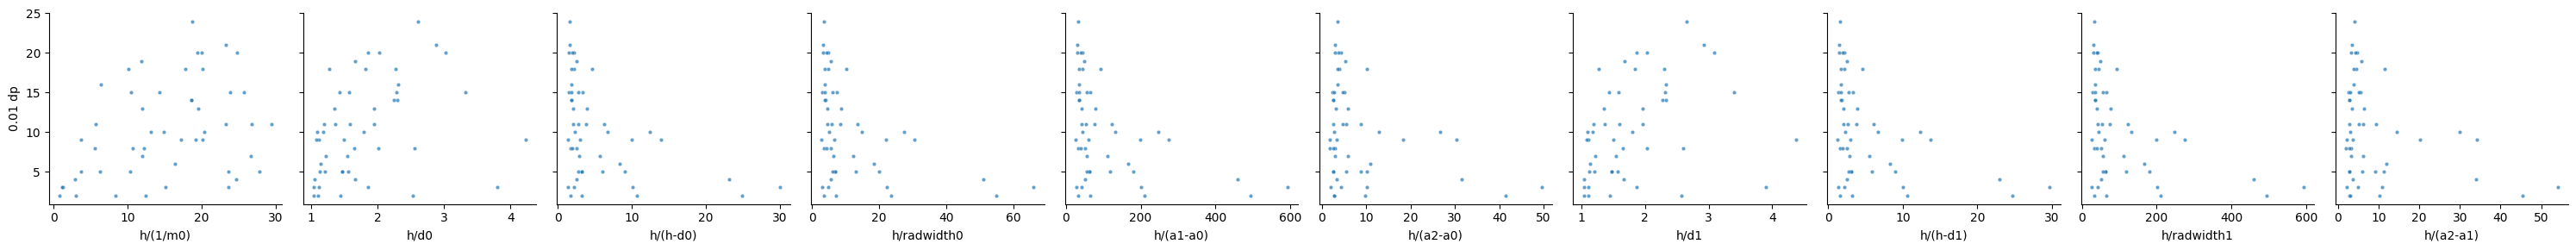

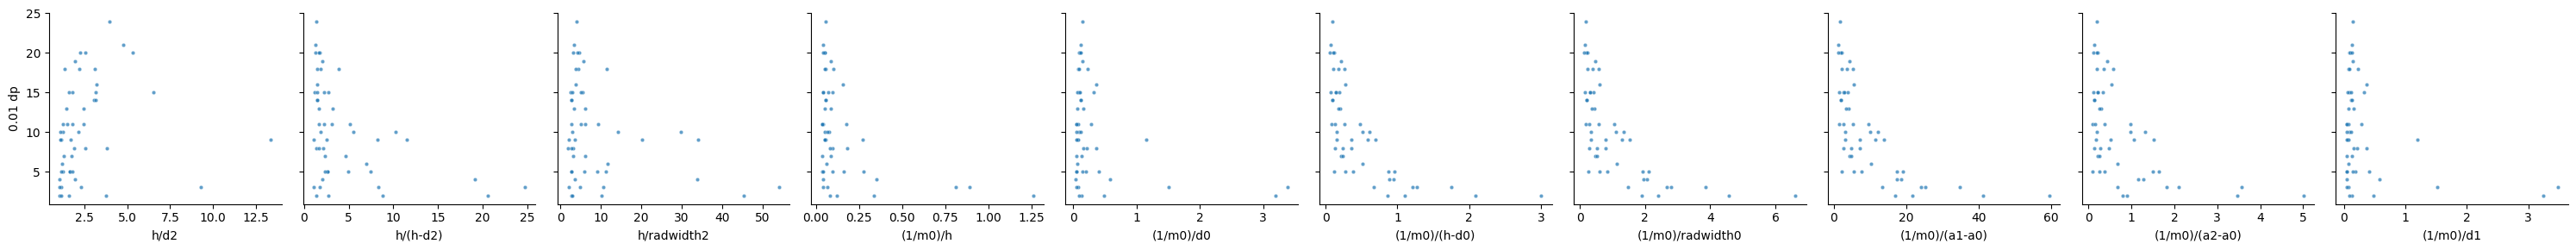

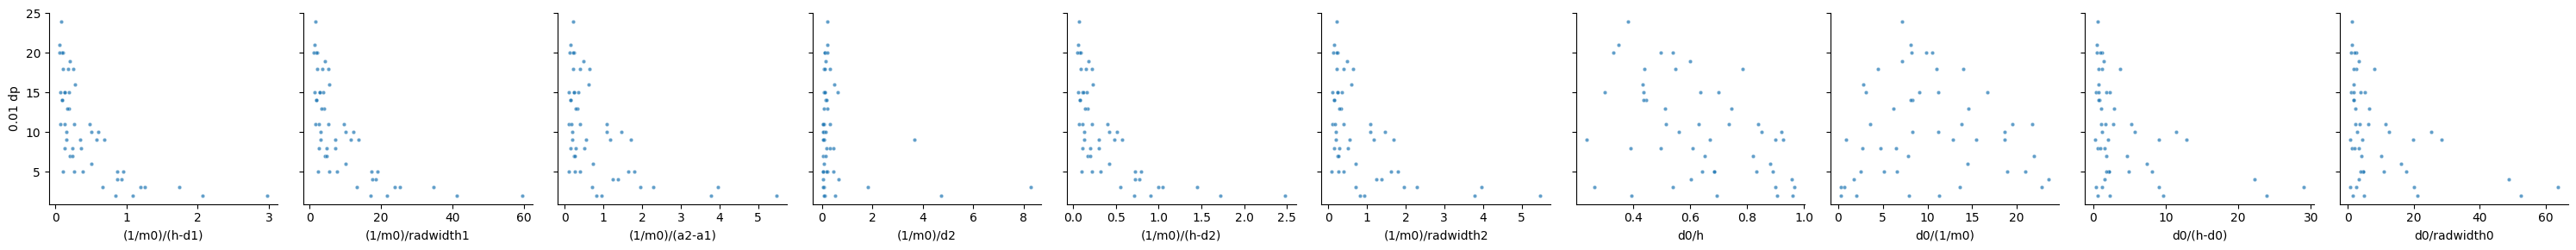

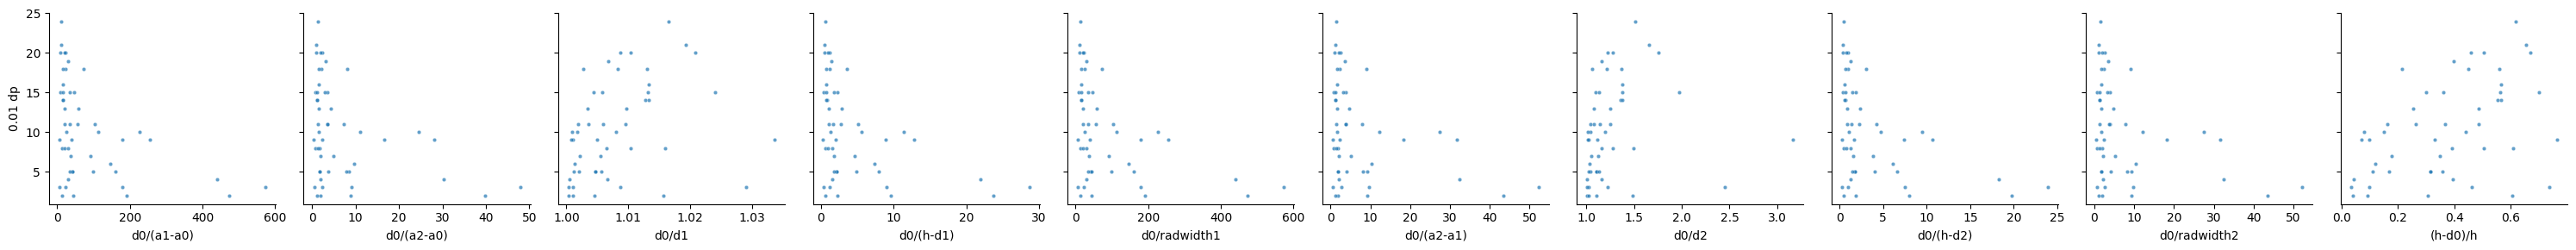

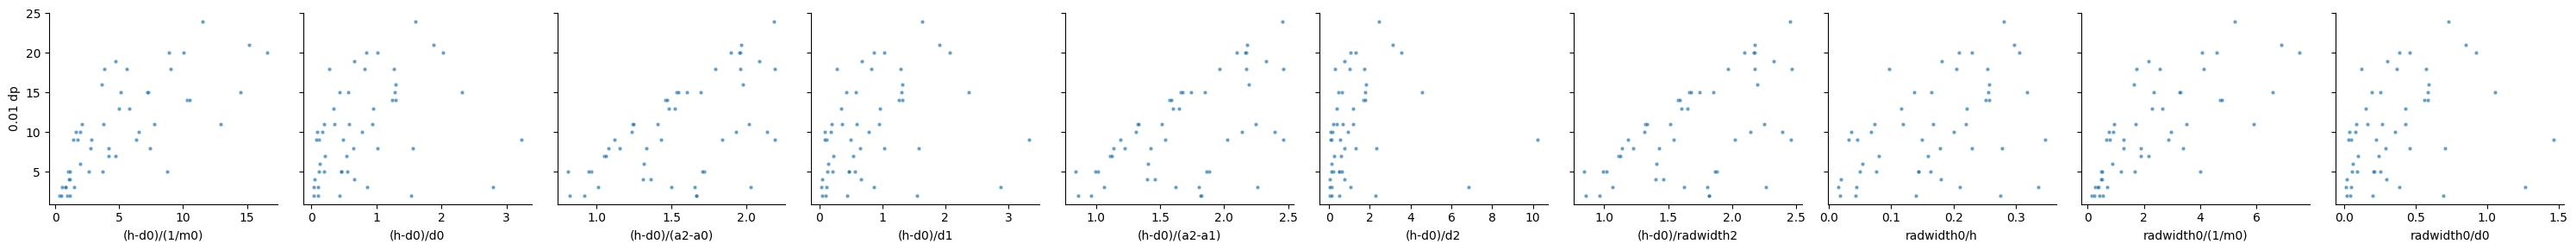

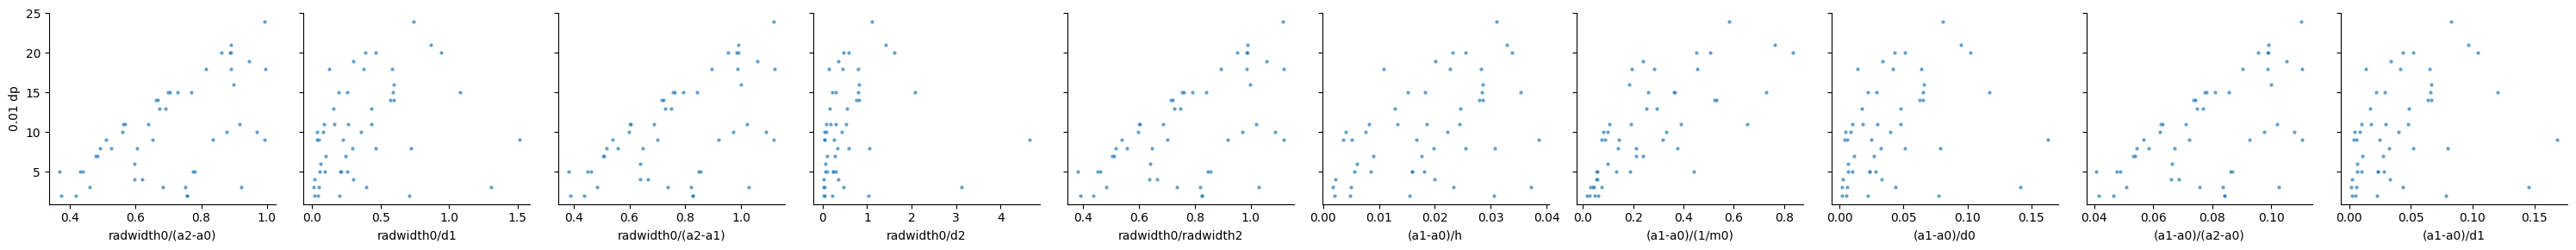

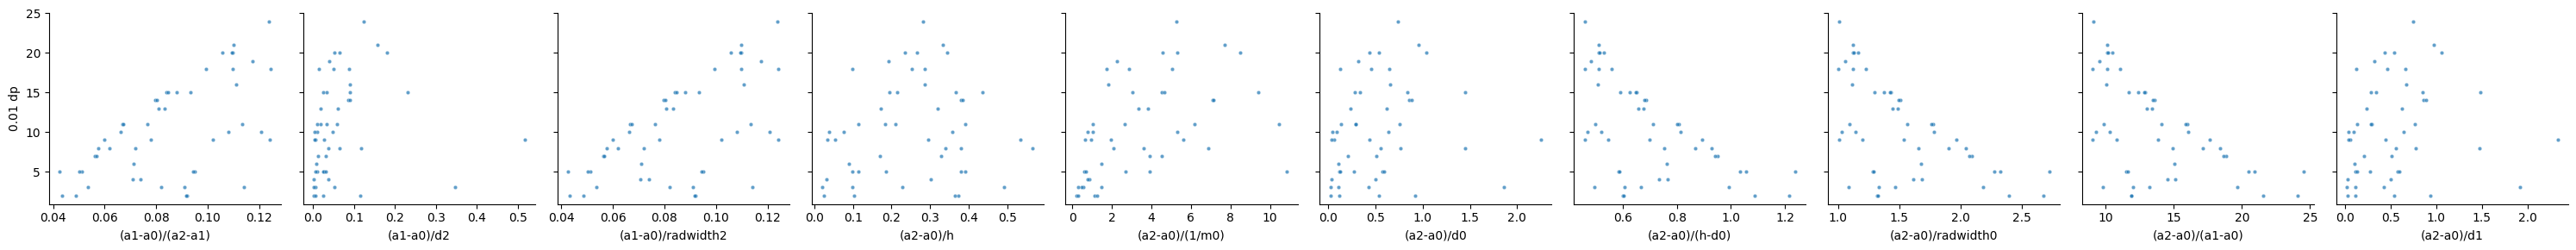

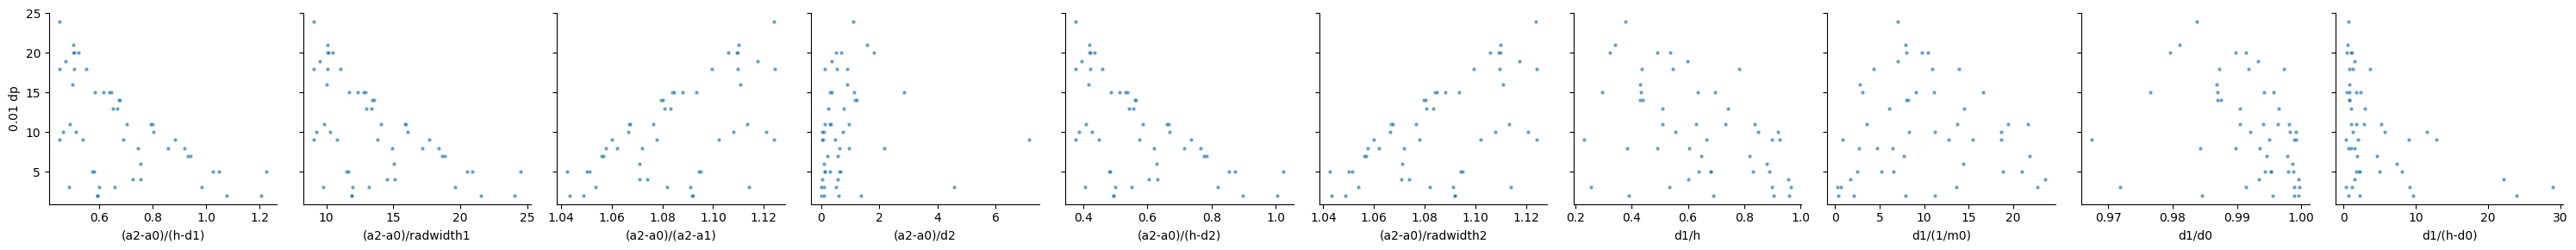

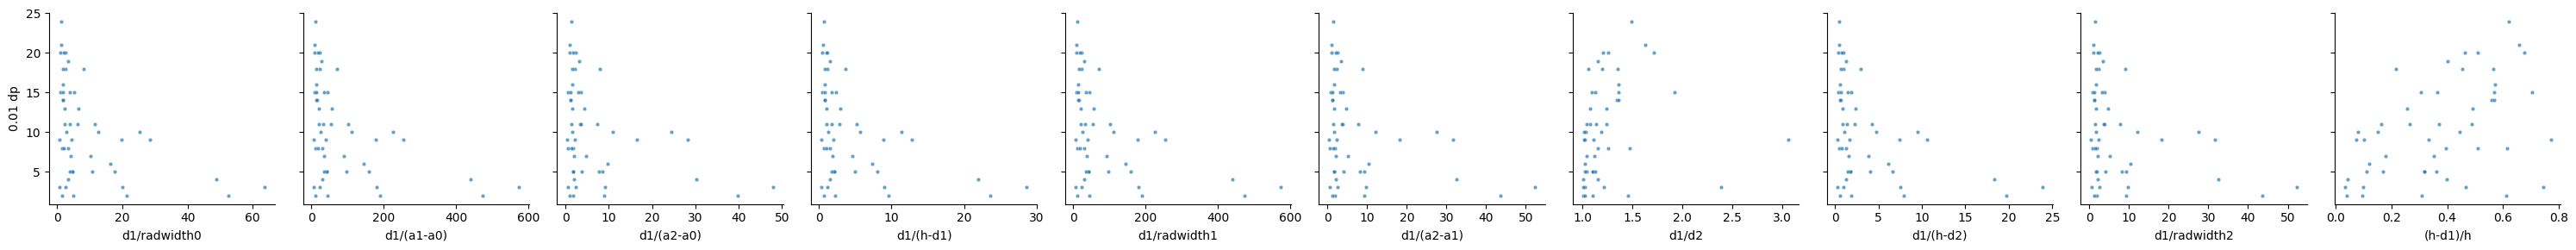

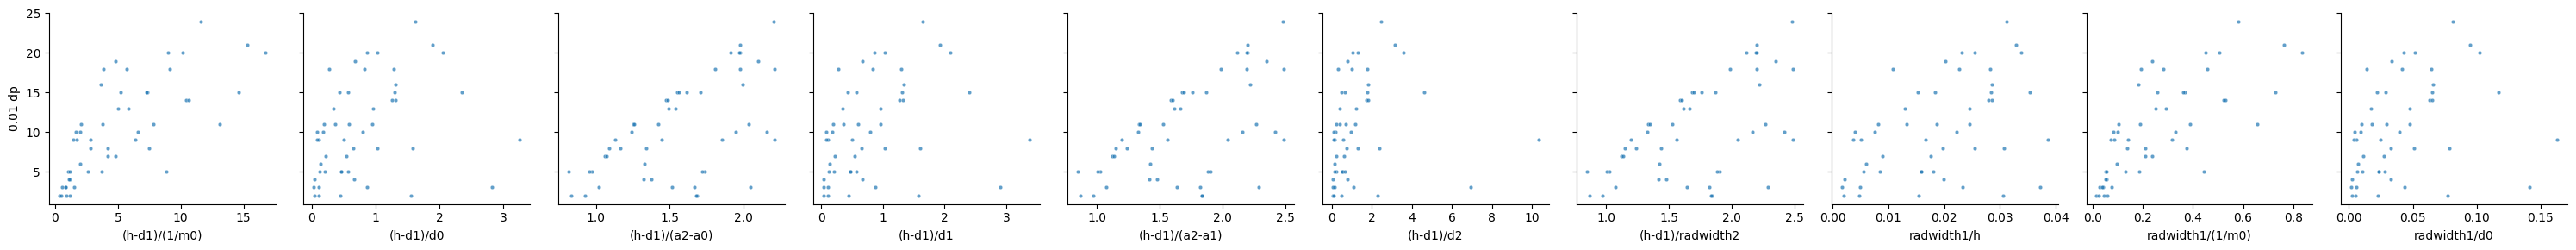

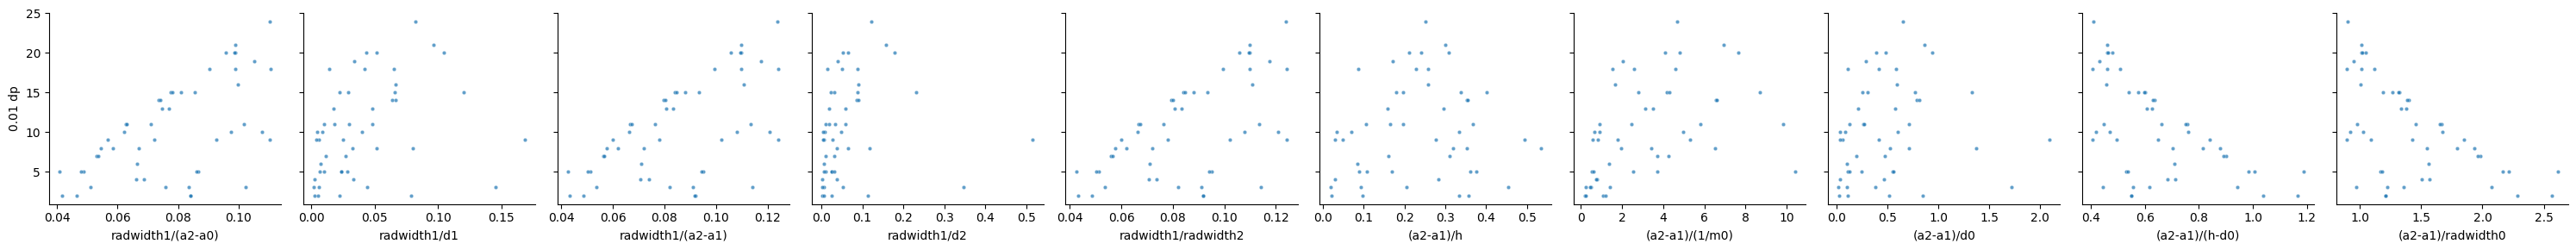

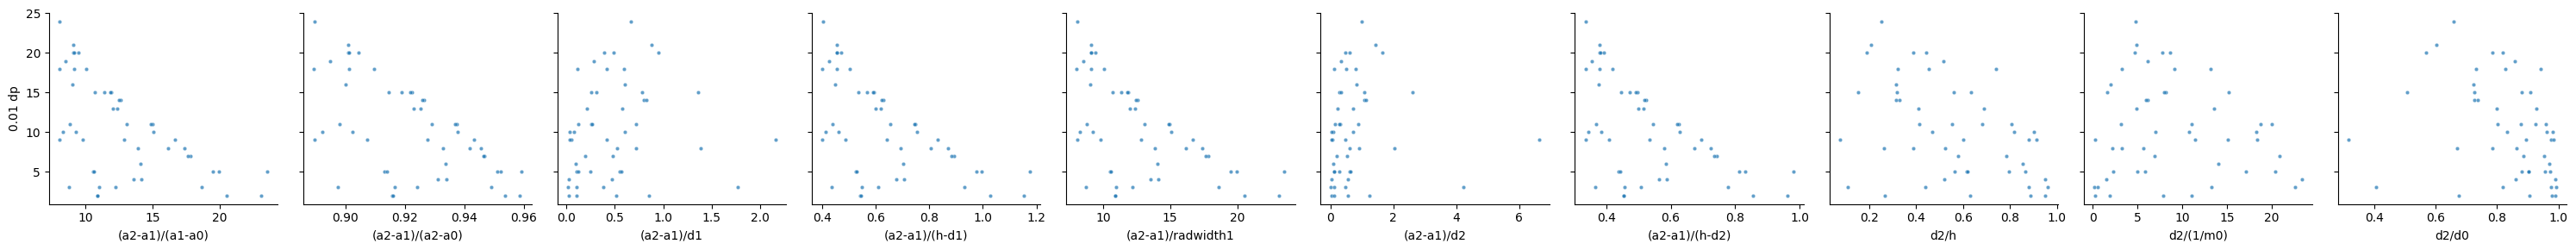

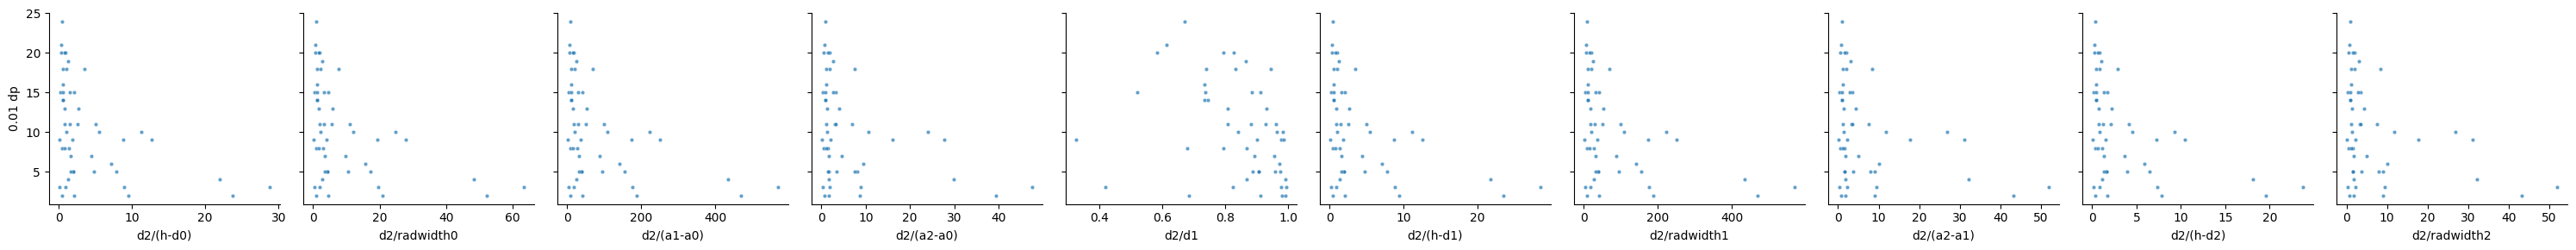

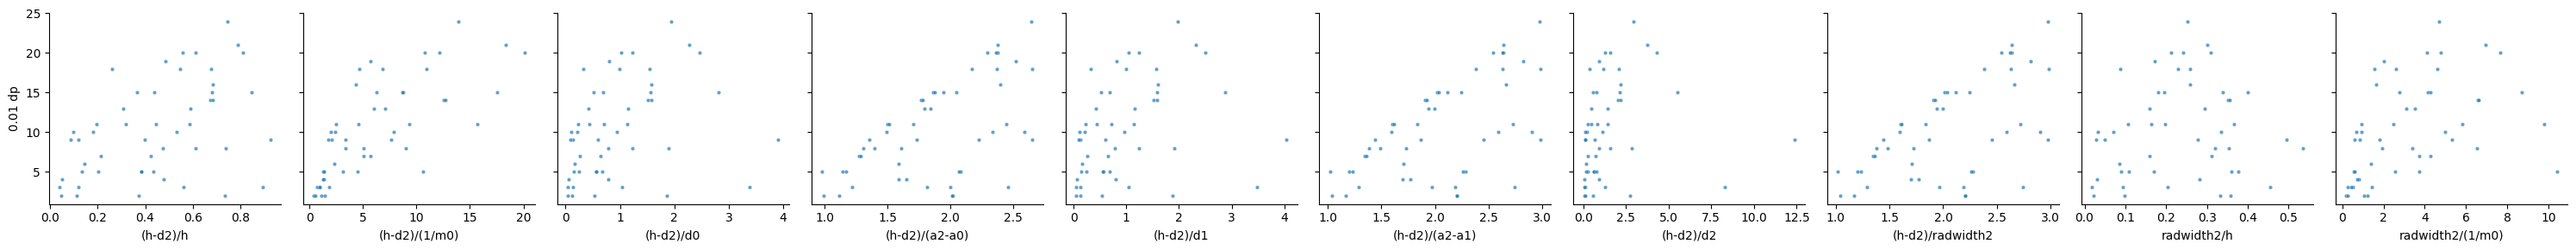

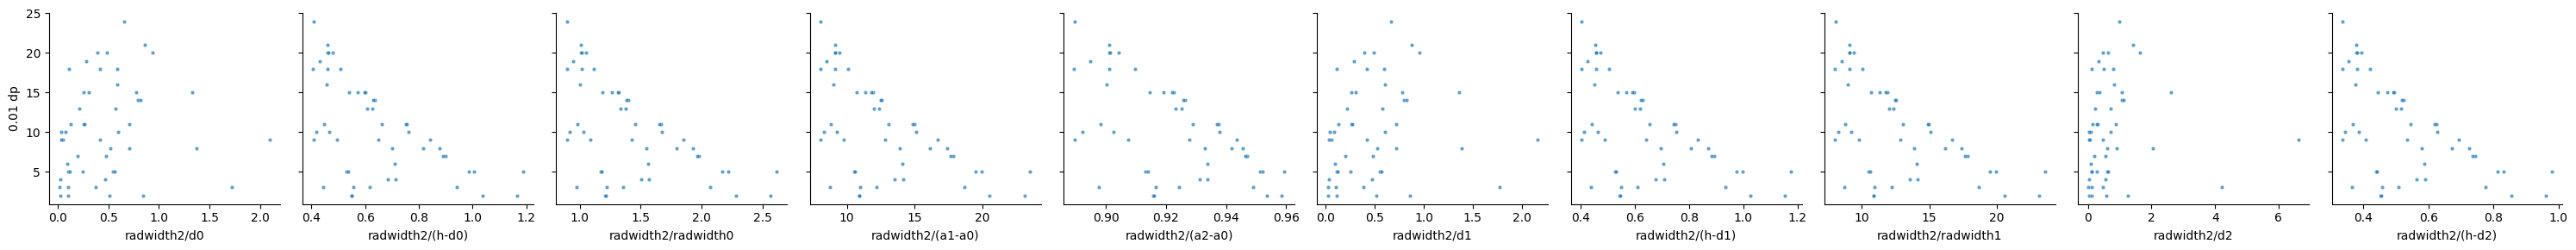

In [8]:
# Plotting all the ratios to narrow down those with shape.
y_funcs = {#"0.01 am" : (lambda data_dict, m0 : data_dict[m0]["convergence point 0.01 am"])}#,
           "0.01 dp" : (lambda data_dict, m0 : data_dict[m0]["convergence point 0.01 dp"])}
count = 0
plot_fs = {}
for func_label in dim0s.keys():
  variable_vals = [dim0s[func_label](suspect, m0) for suspect in suspects for m0 in suspect["m0s"]]
  min_v, max_v = min(variable_vals), max(variable_vals)
  if abs(max_v-min_v)/max_v > 0.00001:
    plot_fs[func_label] = dim0s[func_label]
    count += 1
    if count == 10:
      plot_relation_grid(suspects, plot_fs, y_funcs)
      count, plot_fs = 0, {}
if count != 0:
  plot_relation_grid(suspects, plot_fs, y_funcs)

Plot geometries to visualize what the influential geometry could be.

In [9]:
def plot_varied_cases(fixed_prob_lsts, idx, hydro):
  subset = fixed_prob_lsts[idx].copy()
  val_func = lambda data: data[data["m0s"][0]]["convergence point 0.01 " + hydro]
  subset.sort(key = val_func)
  vals = [val_func(data) for data in subset]
  filter_and_plot_shapes(subset, lambda data_dict, m0 : True, 
                        lambda data_dict, m0 : get_plasma_color(data_dict[m0]["convergence point 0.01 " + hydro], min_value = min(vals), max_value=max(vals)),
                        ppr = 10, figsize_per_plot = (2, 2))
  xs = [data_dict["m0s"][0] *  (data_dict["h"] - data_dict["d"][1]) for data_dict in subset]
  xs = [data_dict["m0s"][0] * (data_dict["a"][2] - data_dict["a"][1]) for data_dict in subset]
  ys = [data_dict[data_dict["m0s"][0]]["convergence point 0.01 " + hydro] for data_dict in subset]
  plt.scatter(xs, ys)
  plt.xlabel("m0 * (h-d)")
  plt.ylabel("convergence point")
  plt.show()

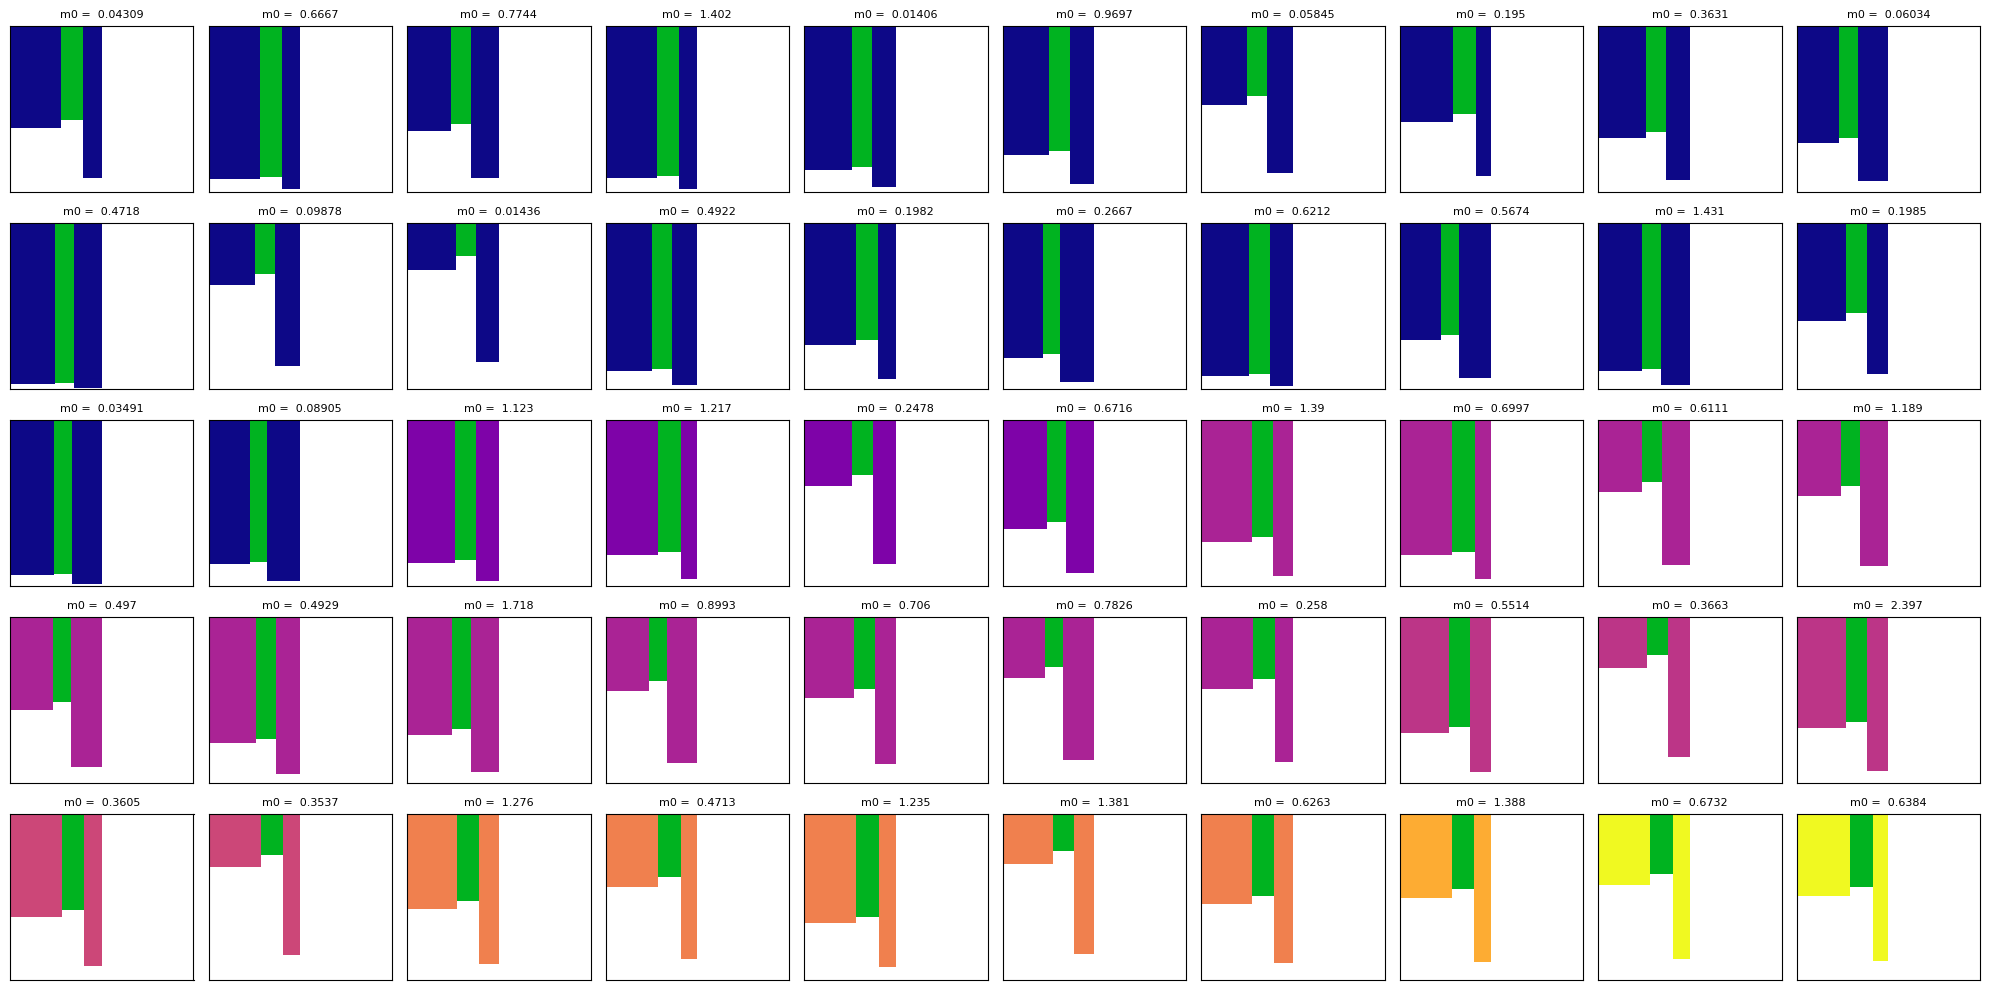

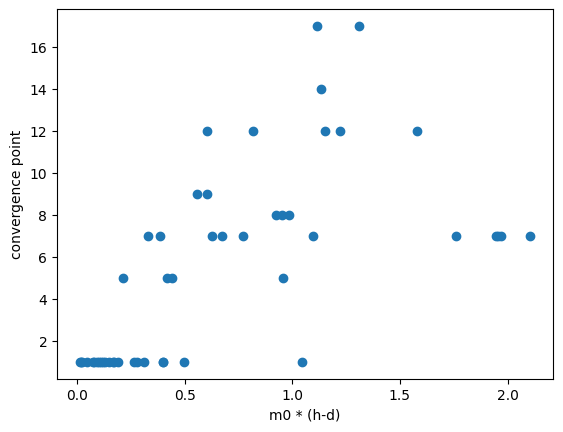

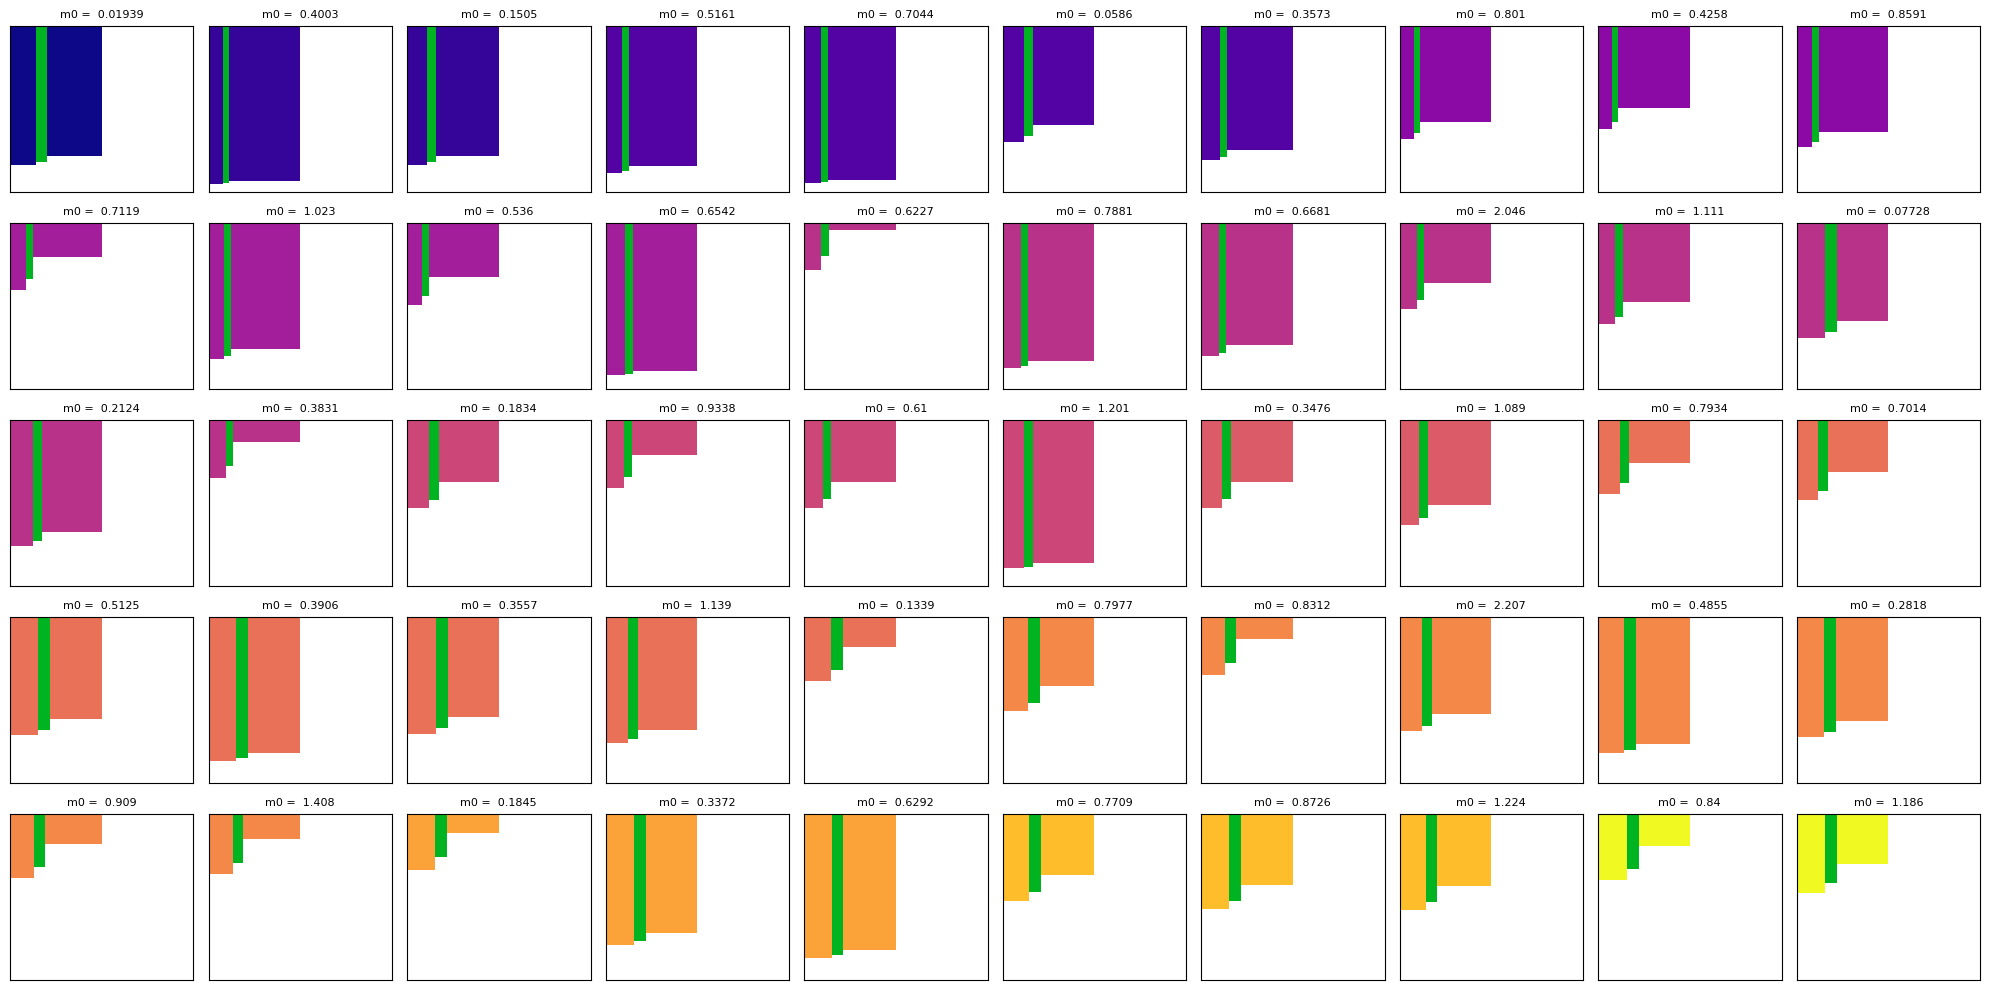

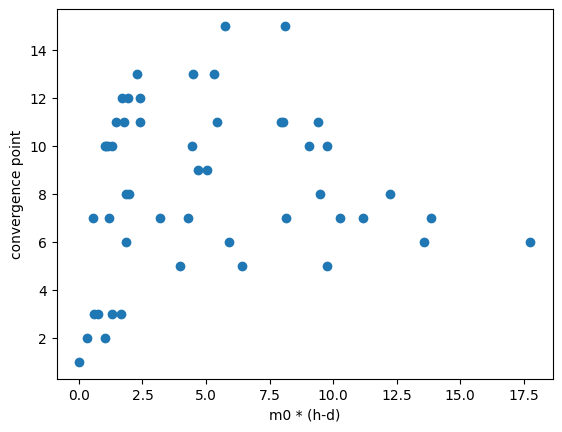

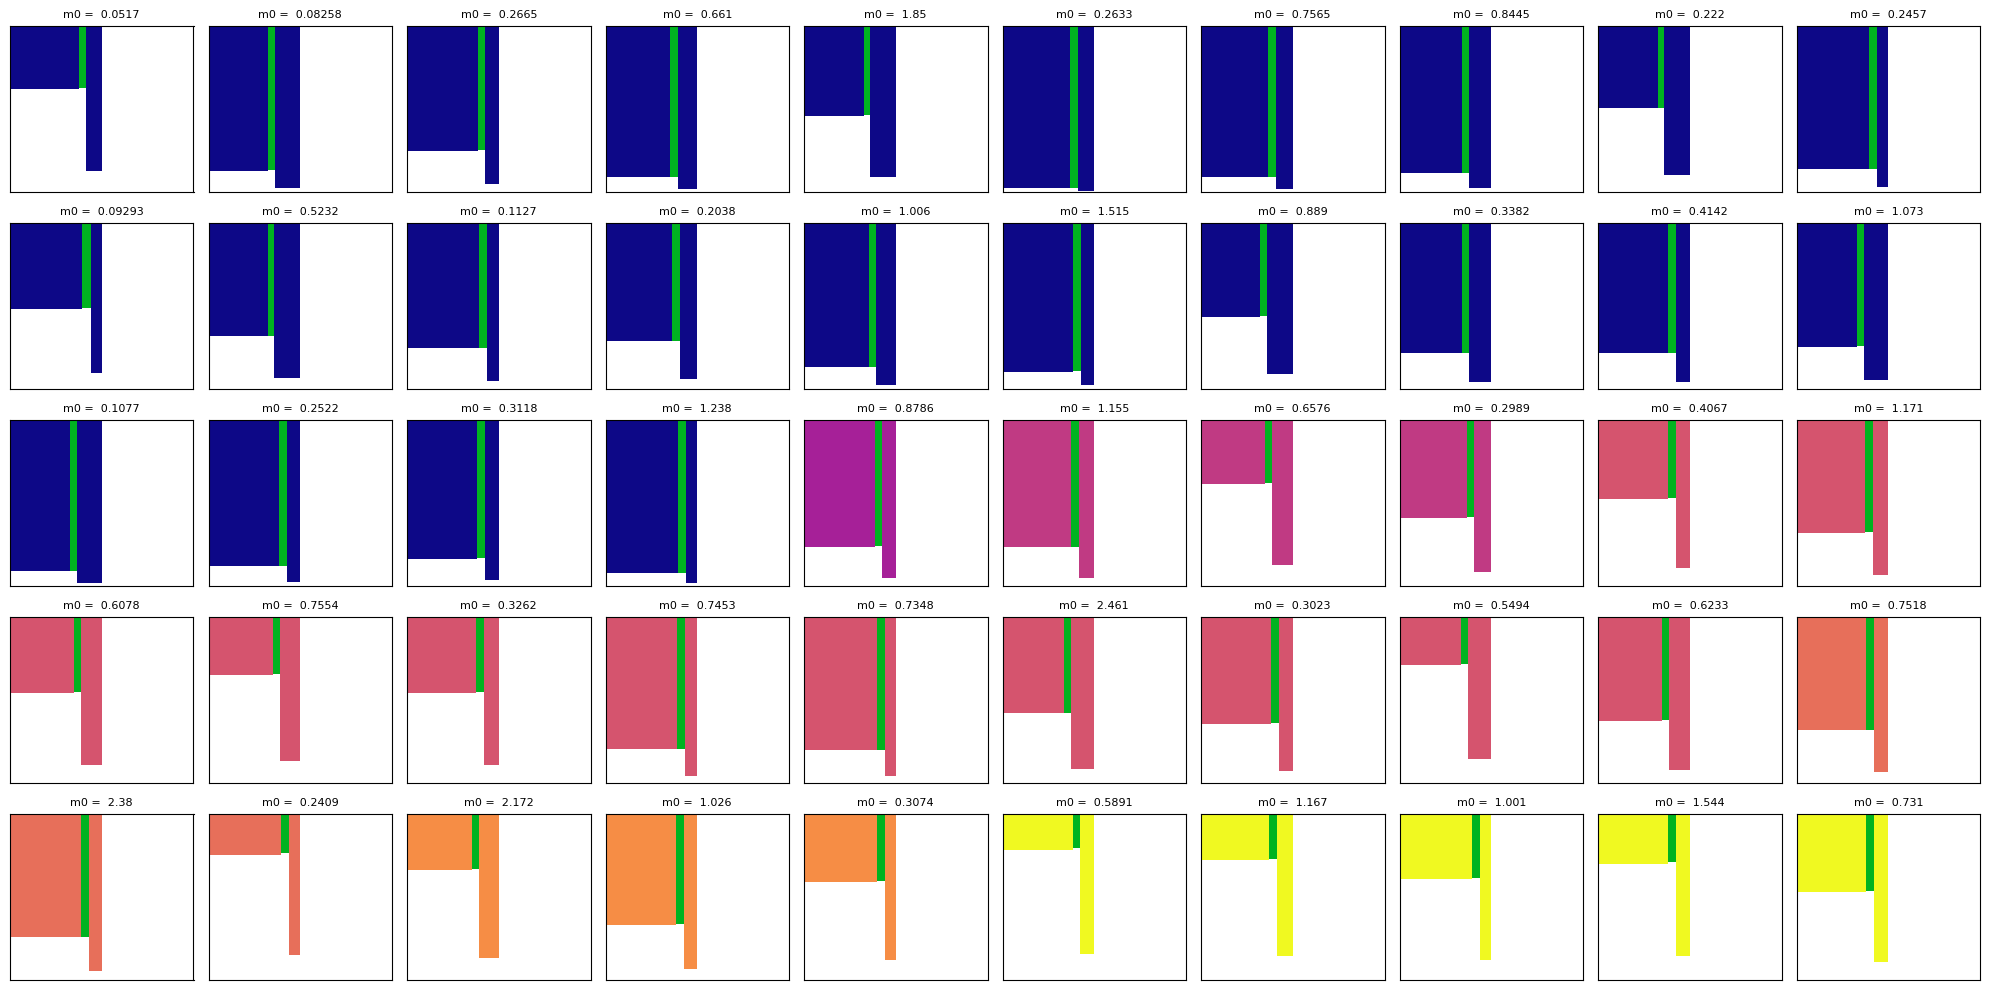

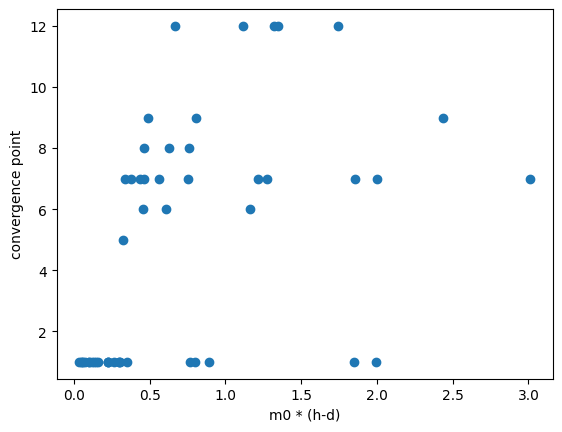

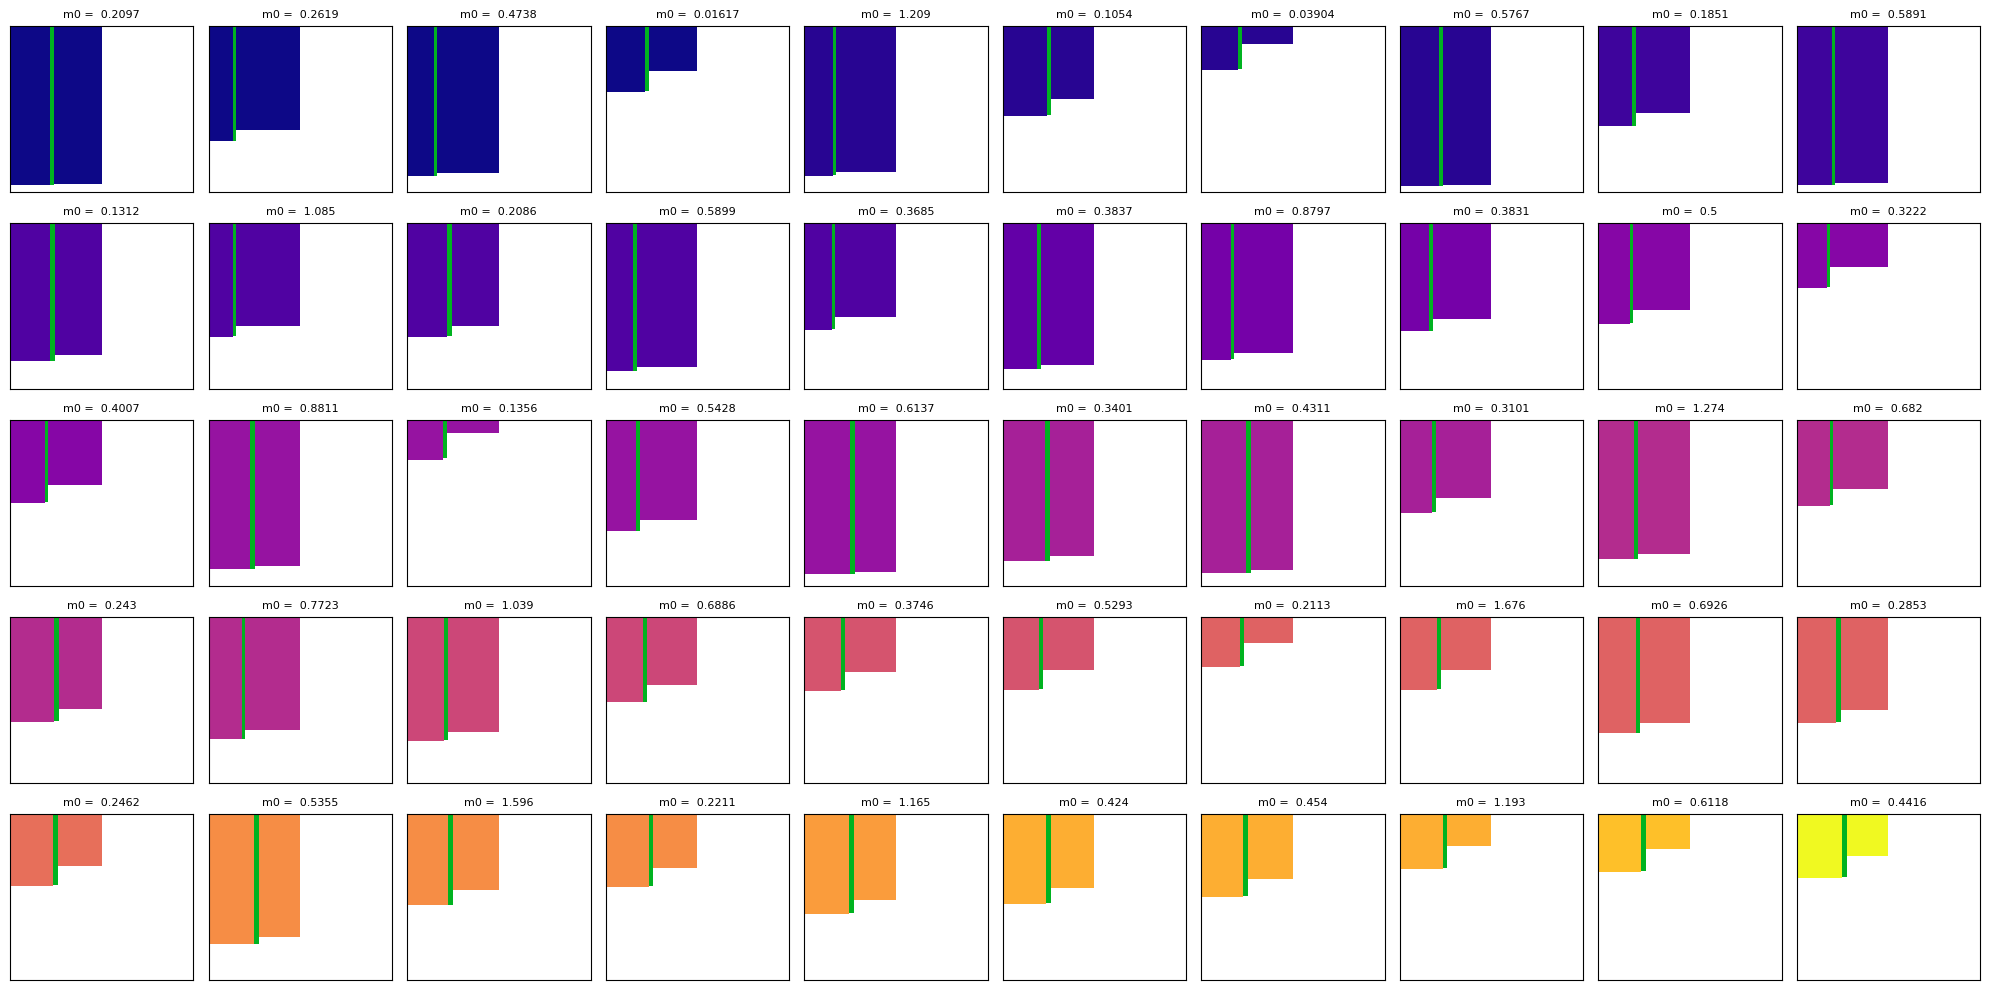

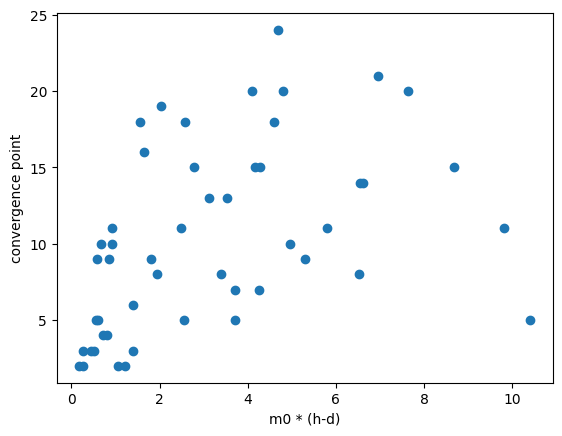

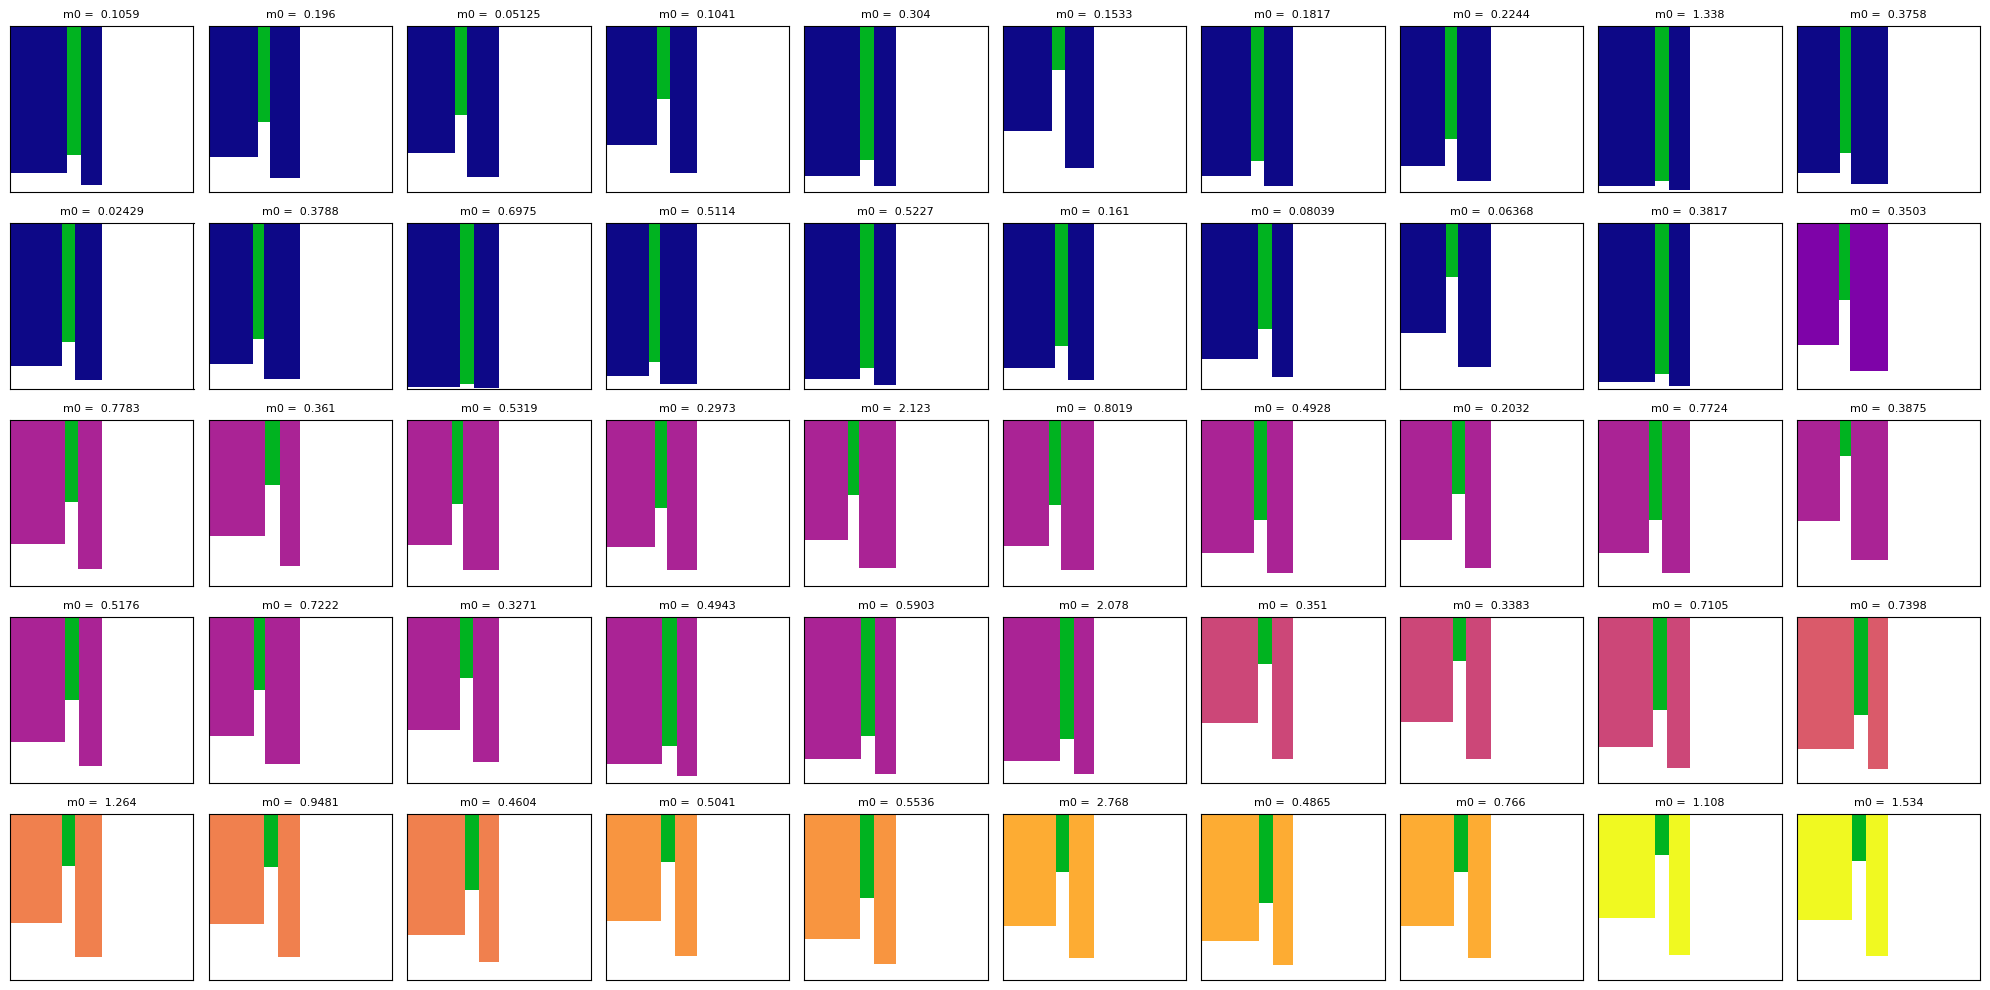

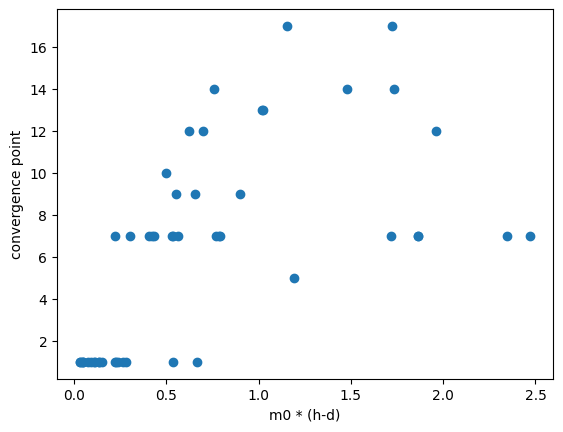

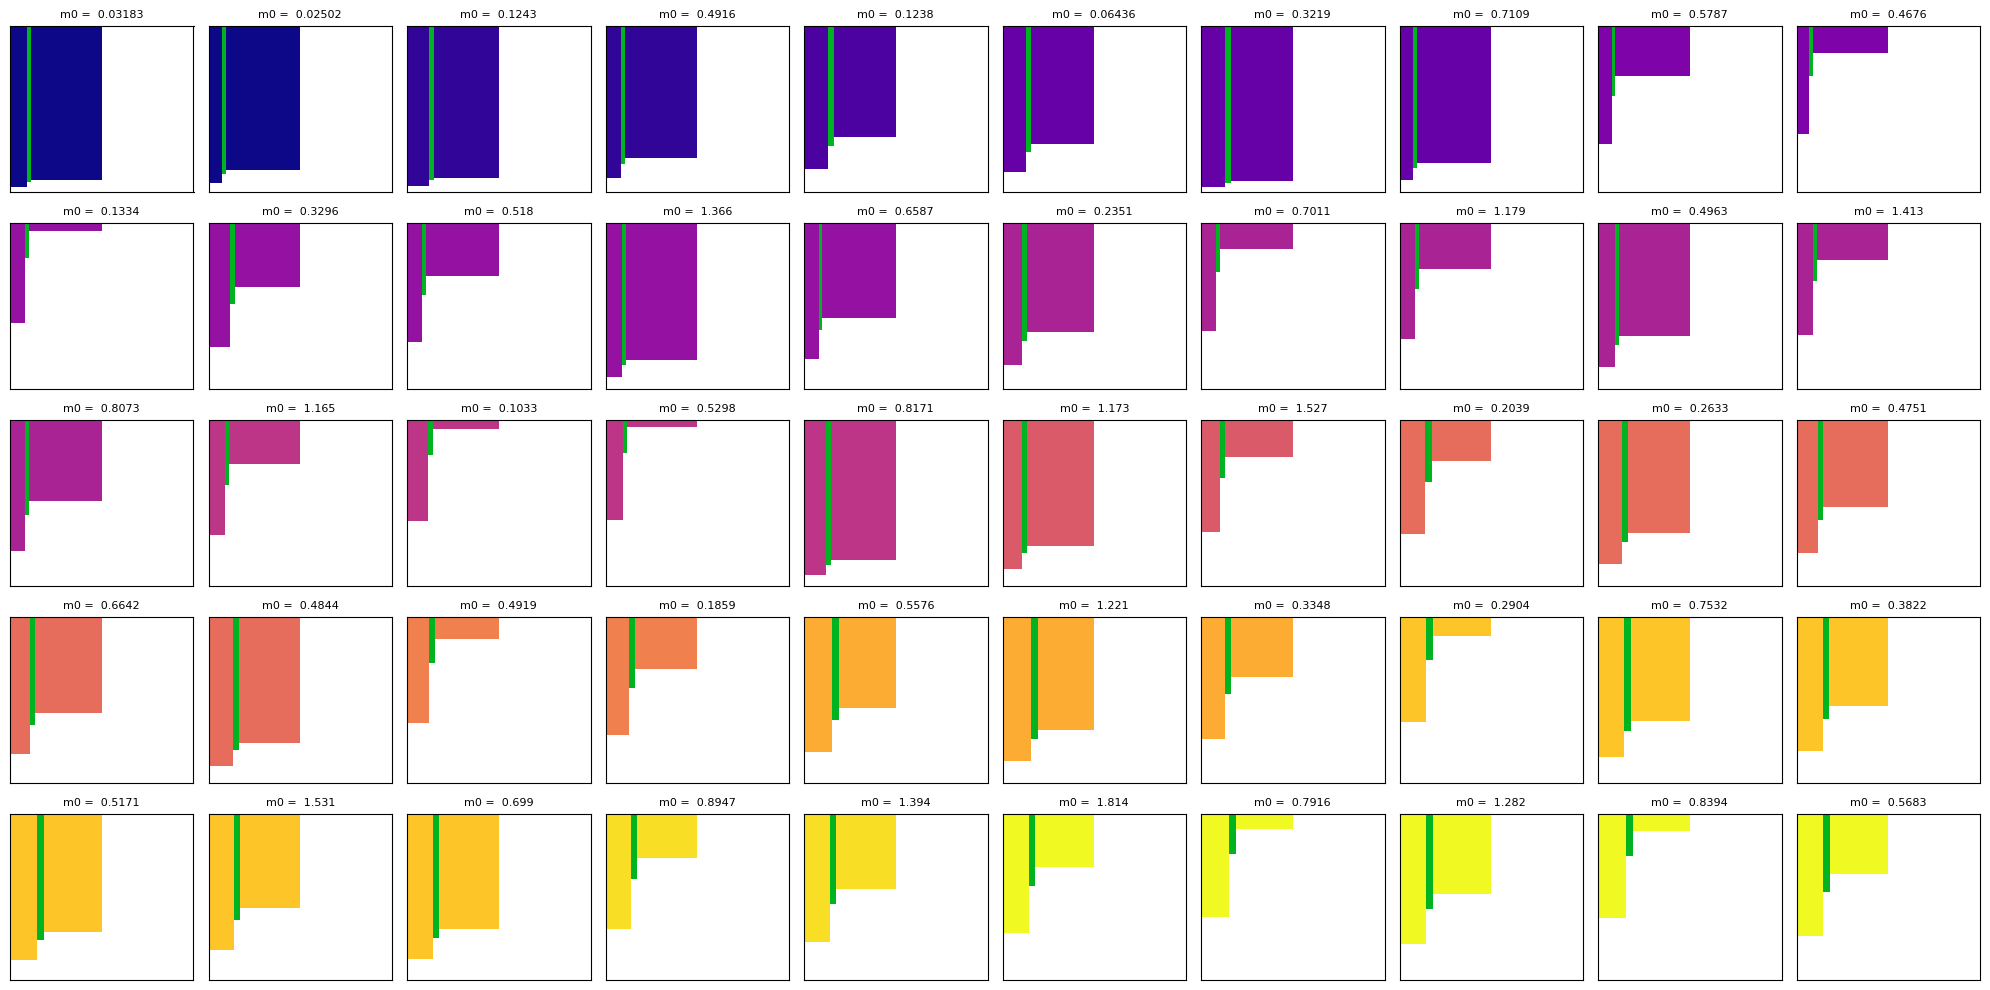

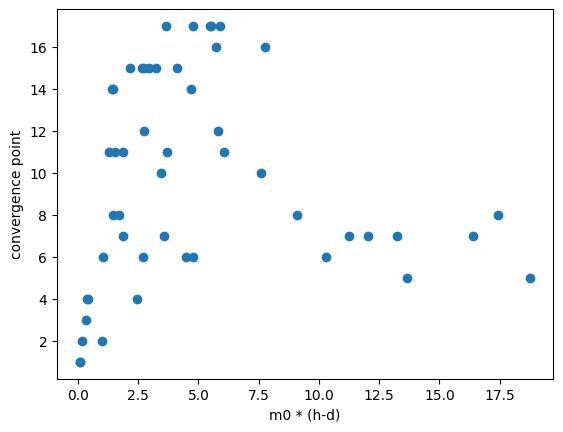

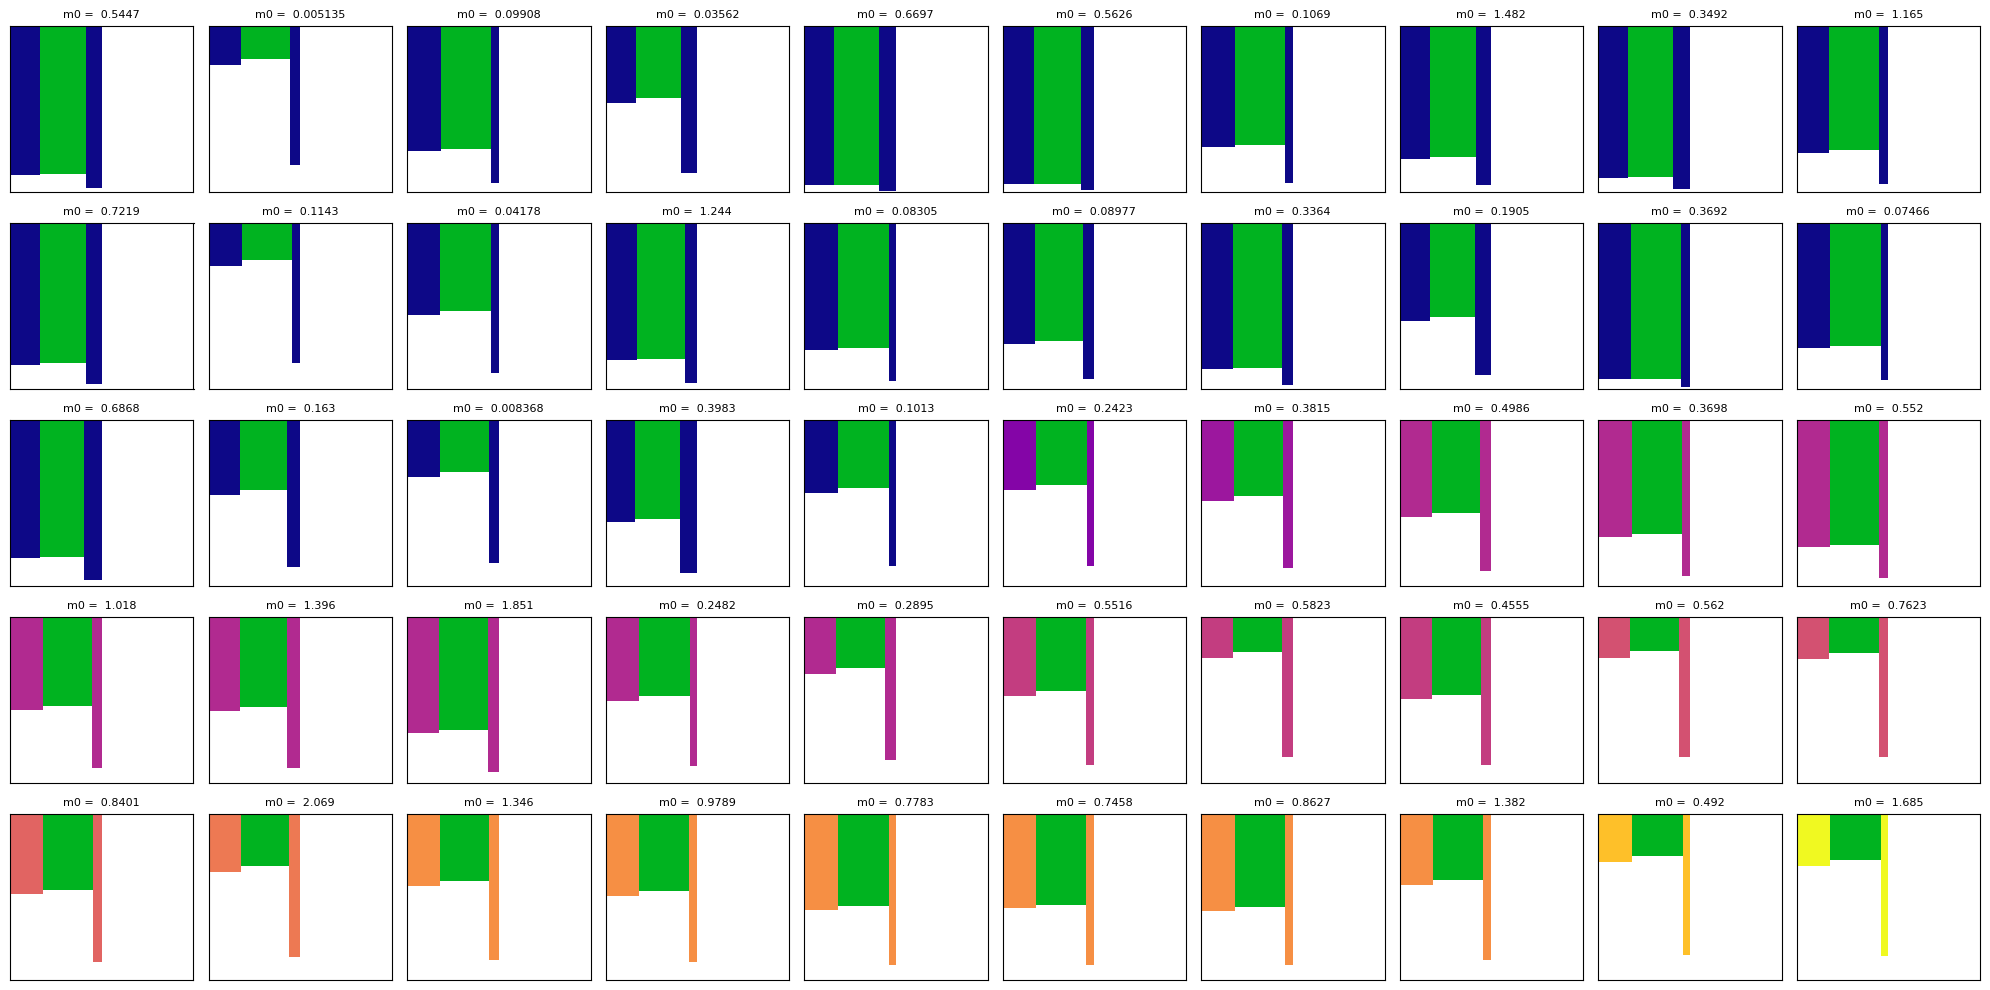

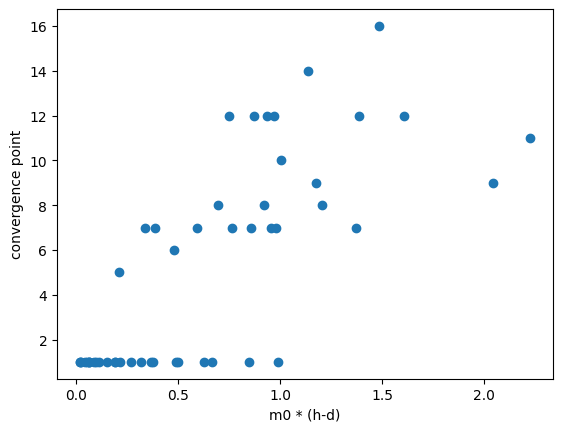

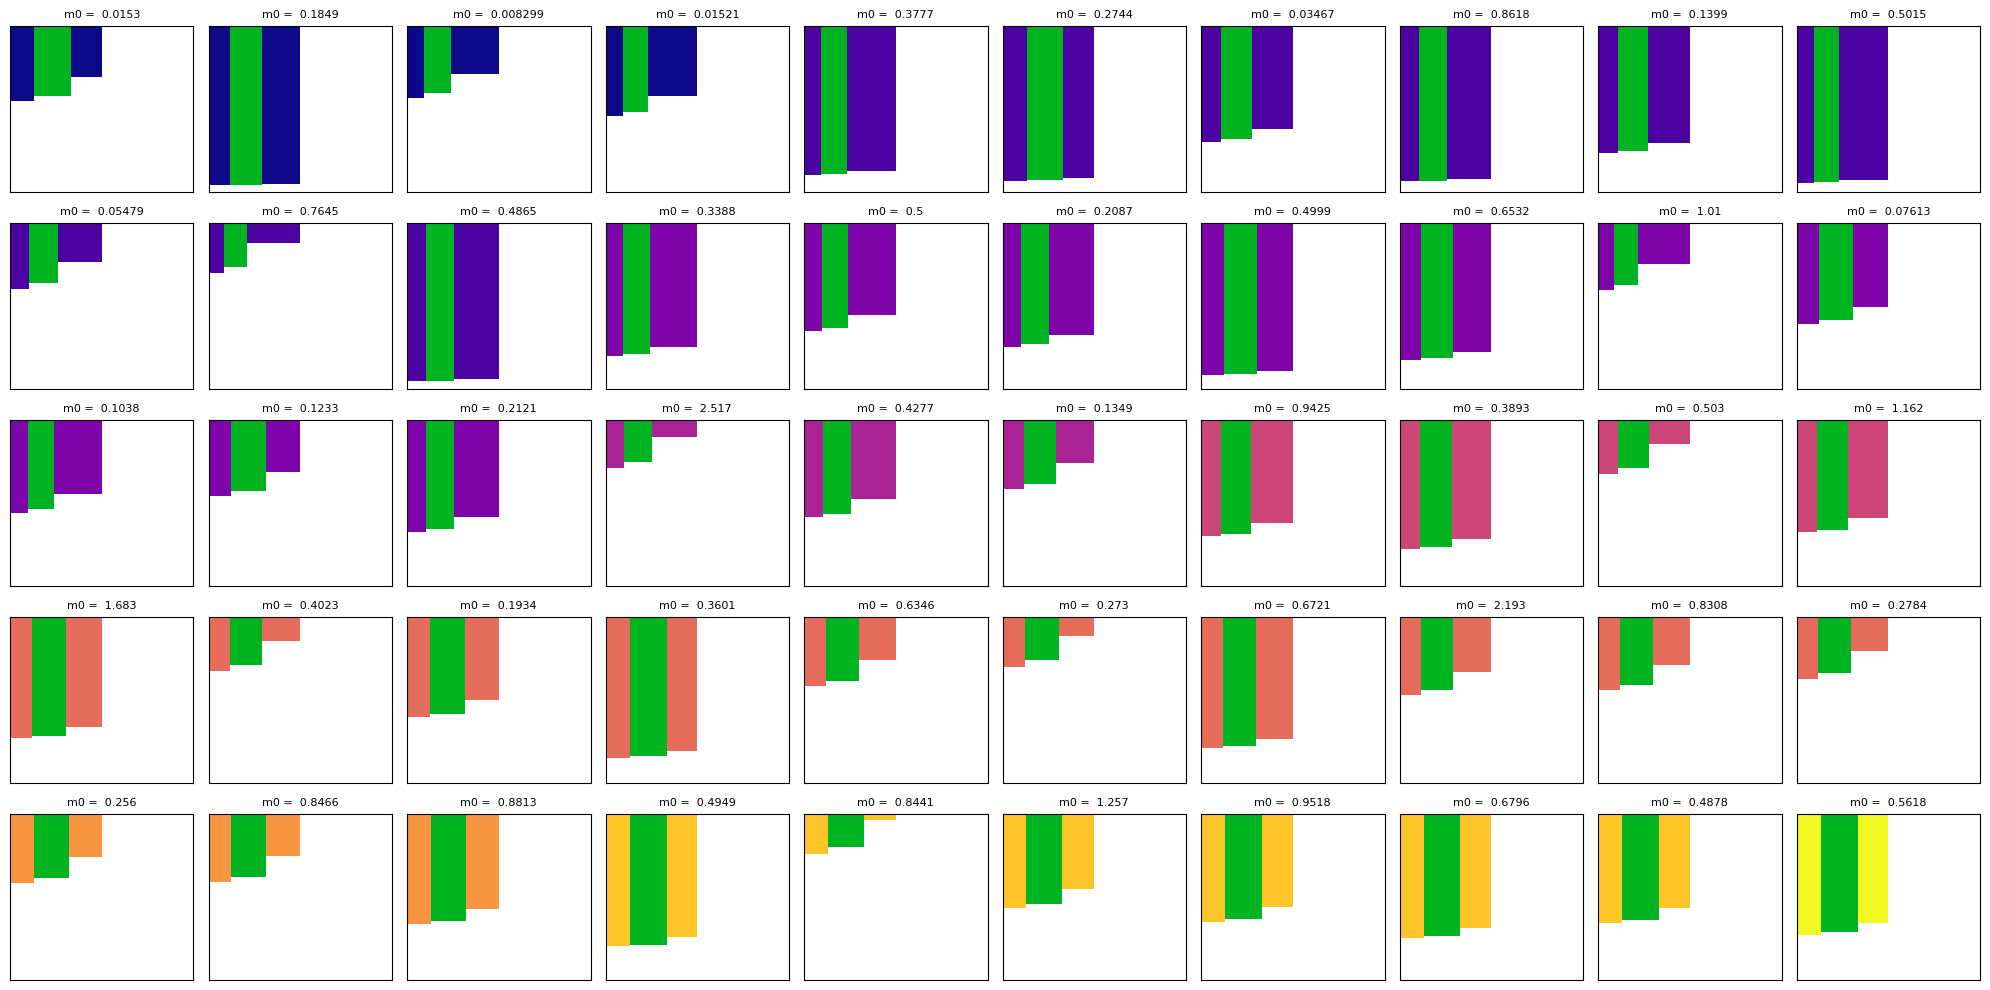

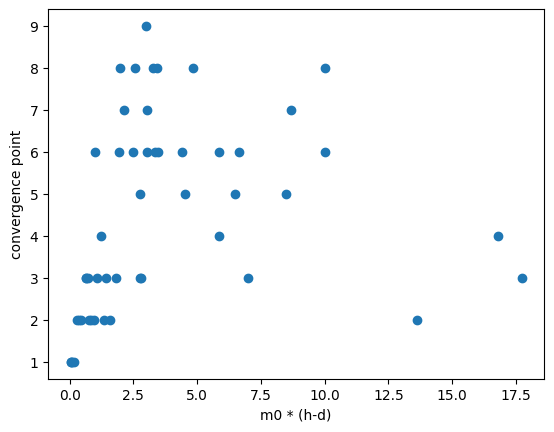

In [10]:
for idx in dp_wide_variation_cases:
  plot_varied_cases(fixed_prob_lsts, idx, "dp")

In [13]:
# raw data generation / data loading and convergence metrics (file2) 

# Vary components individually or in pairs.
predet_left_ratios = [0.5, 0.99, 1.2]
predet_right_ratios = [0.5, 0.99, 1.2]
predet_hmdrs = [1, 2]
predet_rad_ratios = [0.05, 0.1, 0.15]

left_ratios = list(np.linspace(0.1, 0.8, 8)) + list(np.linspace(0.9, 1.1, 21)) + list(np.linspace(1.2, 2, 9))
right_ratios = list(np.linspace(0.1, 0.8, 8)) + list(np.linspace(0.9, 1.1, 21)) + list(np.linspace(1.2, 2, 9))
hmdrs = list(np.linspace(2, 20, 10))
rad_ratios = list(np.linspace(0.01, 0.1, 10)) + list(np.linspace(0.2, 0.6, 9))

# all_data = {"(h-d)/radwidth" : [],
#             "rad ratio" : [],
#             "height ratios" : []}

fixed_for_hmdr = [(left_r, right_r, rad_r) for left_r in predet_left_ratios
                  for right_r in predet_right_ratios for rad_r in predet_rad_ratios] # size = 27
fixed_for_radr = [(left_r, right_r, hmdr) for left_r in predet_left_ratios
                  for right_r in predet_right_ratios for hmdr in predet_hmdrs]
fixed_for_heightr = [(20, 0.1)]

def populate_predet_d_a(h, left_ratio, right_ratio, hmdr, rad_ratio):
  hmd1 = 10
  hmd0 = left_ratio * hmd1
  hmd2 = right_ratio * hmd1

  radwidth1 = hmd1/hmdr
  radwidth0 = radwidth1 * (1/rad_ratio - 1)
  radwidth2 = hmd2/3
  hmds = [hmd0, hmd1, hmd2]
  radwidths = [radwidth0, radwidth1, radwidth2]
  d = [h - hmds[i] for i in range(3)]
  a = [sum(radwidths[:i + 1]) for i in range(3)]
  return d, a

def solve_and_store(h, m0, mk, prob, nmk_max, d, a, region = 1):
  info = {"h" : h,
          "d" : d,
          "a" : a,
          "region" : region,
          "m0s" : [m0]}
  print(info)
  swap_vals(prob, d, a)
  return merge_dicts(info, prob.convergence_study_over_m0s(nmk_max, [m0], [mk]))

h = 30
m0 = 1

big_nmk = 200
nmk_max = 150
NMK = [big_nmk] * 4
heaving = [0, 1, 0]
rho = 1023

# prob = ConvergenceProblemI(h, [1,1,1], [1,2,3], heaving, NMK, m0, rho)
# mk = prob.m_k

# for triple in fixed_for_hmdr:
#   for hmdr in hmdrs:
#     d, a = populate_predet_d_a(h, triple[0], triple[1], hmdr, triple[2])
#     data_dict = solve_and_store(h, m0, mk, prob, nmk_max, d, a)
#     all_data["(h-d)/radwidth"].append(data_dict)
#   update_data_file(all_data, file2)
#   print("Finished an hmdr triple.")

# for triple in fixed_for_radr:
#   for rad_ratio in rad_ratios:
#     d, a = populate_predet_d_a(h, triple[0], triple[1], triple[2], rad_ratio)
#     data_dict = solve_and_store(h, m0, mk, prob, nmk_max, d, a)
#     all_data["rad ratio"].append(data_dict)
#   update_data_file(all_data, file2)
#   print("Finished a rad ratio triple.")

# for tup in fixed_for_heightr: # just 1
#   for left_ratio in left_ratios:
#     for right_ratio in right_ratios:
#       d, a = populate_predet_d_a(h, left_ratio, right_ratio, tup[0], tup[1])
#       data_dict = solve_and_store(h, m0, mk, prob, nmk_max, d, a)
#       all_data["height ratios"].append(data_dict)
#     update_data_file(all_data, file2)
#     print("Finished a right ratio.")

# # Add better generating data for rad_ratio
# all_data = open_pkl_file(file2)
# rad_ratios = list(np.linspace(0.01, 0.15, 15))
# predet_left_ratios = [0.2, 0.8, 0.9]
# predet_right_ratios = [0.5, 0.99, 1.2]
# prob = ConvergenceProblemI(h, [1,1,1], [1,2,3], heaving, NMK, m0, rho)
# mk = prob.m_k
# fixed_for_radr = [(left_r, right_r, 20) for left_r in predet_left_ratios for right_r in predet_right_ratios]
# for triple in fixed_for_radr:
#   for rad_ratio in rad_ratios:
#     d, a = populate_predet_d_a(h, triple[0], triple[1], triple[2], rad_ratio)
#     data_dict = solve_and_store(h, m0, mk, prob, nmk_max, d, a)
#     all_data["rad ratio"].append(data_dict)
#   update_data_file(all_data, file2)
#   print("Finished a rad ratio triple.")

all_data = open_pkl_file(file2)
log_data = {}
for key in all_data.keys():
  generate_convergence_data(all_data[key], [0.01, 0.005])
  log_data[key] = generate_log_data(all_data[key])


(h-d)/radwidth


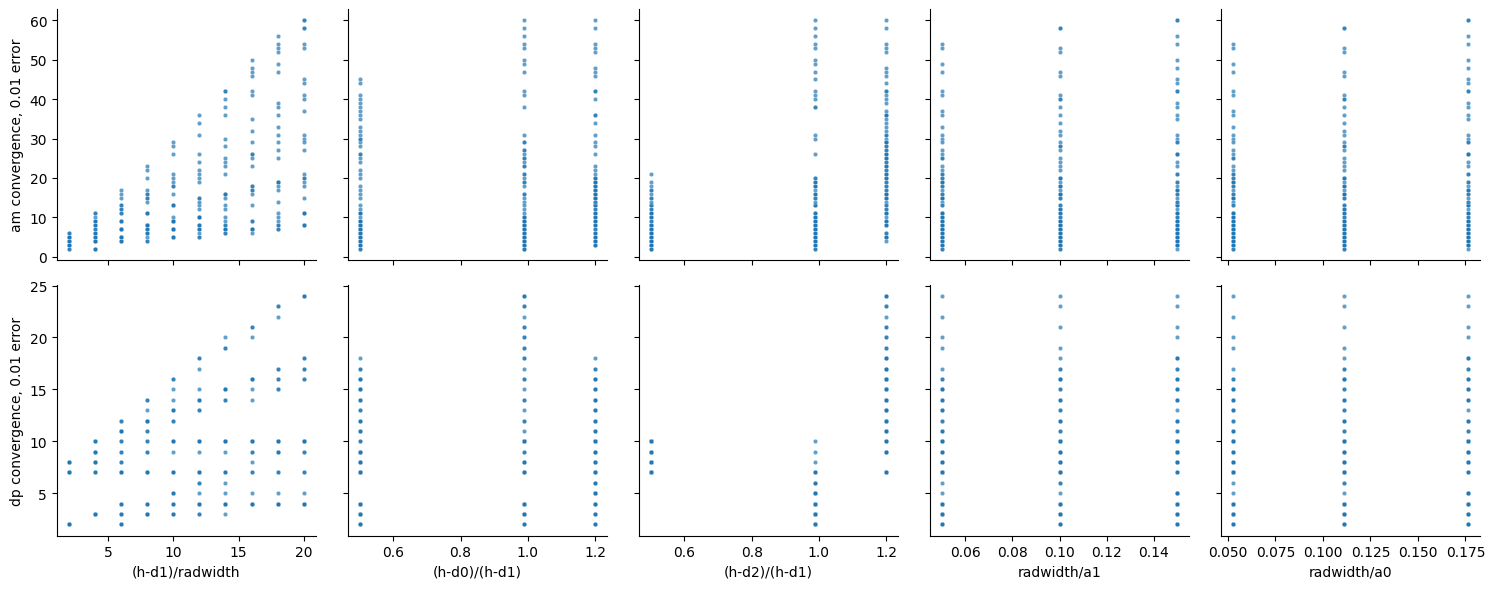

rad ratio


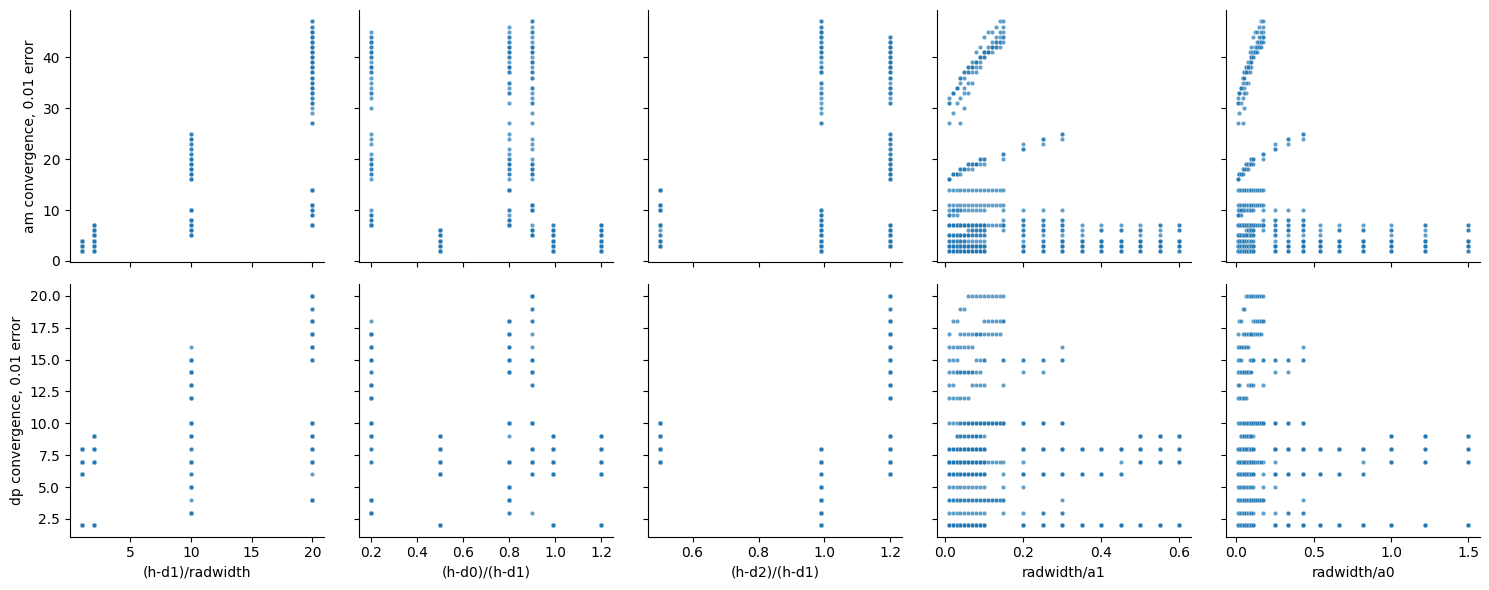

height ratios


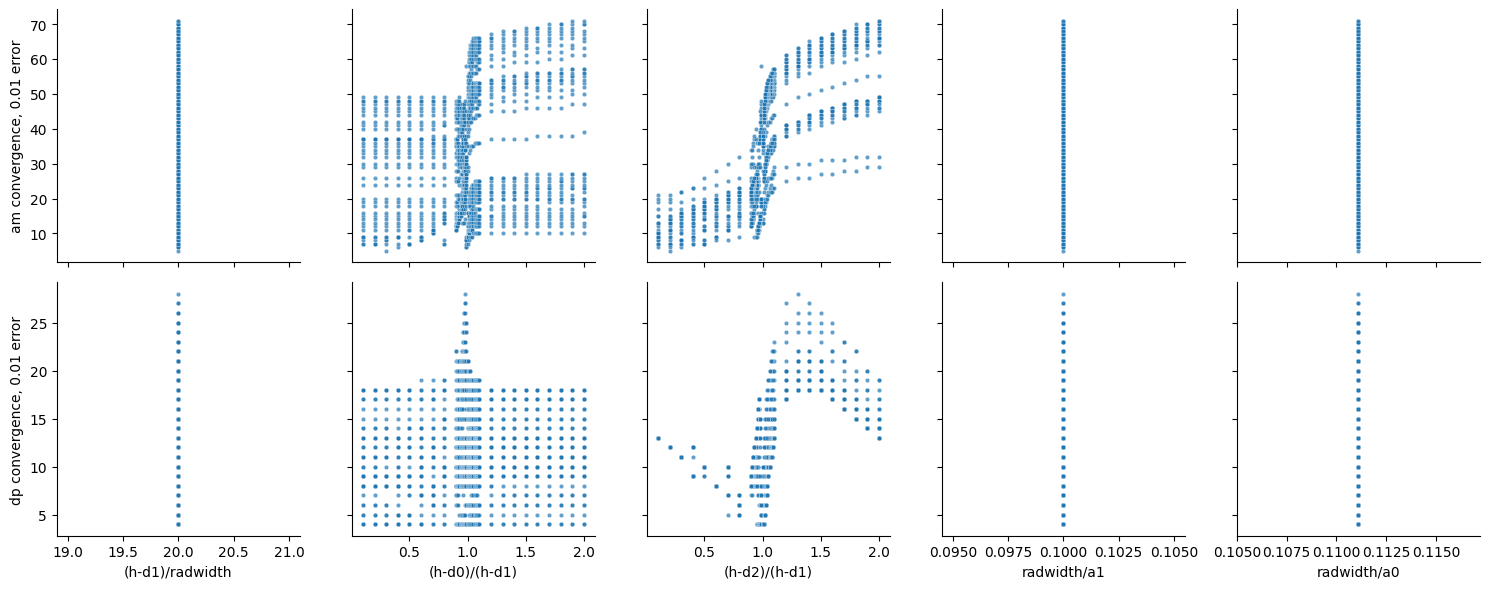

In [14]:
# Plot convergence point on y, various on dimensionless parameters on x.
def xf1(config, m0):
  return (config["h"] - config["d"][1])/(config["a"][1] - config["a"][0])

def xf2(config, m0):
  return (config["h"] - config["d"][0])/(config["h"] - config["d"][1])

def xf3(config, m0):
  return (config["h"] - config["d"][2])/(config["h"] - config["d"][1])

def xf4(config, m0):
  return (config["a"][1] - config["a"][0])/(config["a"][1])

def xf5(config, m0):
  return (config["a"][1] - config["a"][0])/(config["a"][0])

def yf1(config, m0):
  return config[m0]["convergence point 0.01 am"]

def yf2(config, m0):
  return config[m0]["convergence point 0.005 am"]

def yf3(config, m0):
  return config[m0]["convergence point 0.01 dp"]

def yf4(config, m0):
  return config[m0]["convergence point 0.005 dp"]

x_funcs = {"(h-d1)/radwidth" : xf1,
           "(h-d0)/(h-d1)" : xf2,
           "(h-d2)/(h-d1)" : xf3,
           "radwidth/a1" : xf4,
           "radwidth/a0" : xf5}
y_funcs = {"am convergence, 0.01 error" : yf1,
          #  "am convergence, 0.005 error" : yf2,
           "dp convergence, 0.01 error" : yf3,
          #  "dp convergence, 0.005 error" : yf4
           }

for key in all_data.keys():
  print(key)
  plot_relation_grid(all_data[key], x_funcs, y_funcs)


In [15]:
# dimensionless parameter functions
def h_minus_d_over_radwidth(data_dict):
    region = data_dict["region"]
    radwidth = data_dict["a"][0] if region == 0 else (data_dict["a"][region] - data_dict["a"][region - 1])
    return (data_dict["h"] - data_dict["d"][region])/radwidth

def tall_theta(data_dict):
  hmdr = h_minus_d_over_radwidth(data_dict)
  return np.arctan(1/hmdr)

def right_ratio(data_dict):
  region = data_dict["region"]
  if region == (len(data_dict["d"]) - 1):
     return data_dict["h"]/(data_dict["h"] - data_dict["d"][region])
  else:
    return (data_dict["h"] - data_dict["d"][region + 1])/(data_dict["h"] - data_dict["d"][region])
    
def left_ratio(data_dict):
  region = data_dict["region"]
  if region == 0:
     return 0
  else:
    return (data_dict["h"] - data_dict["d"][region - 1])/(data_dict["h"] - data_dict["d"][region])
  
def rad_ratio(data_dict):
  region = data_dict["region"]
  radwidth = data_dict["a"][0] if region == 0 else (data_dict["a"][region] - data_dict["a"][region - 1])
  return radwidth/data_dict["a"][region]

def restrict(all_data, f, val):
  return [data_dict for data_dict in all_data if (abs(f(data_dict) - val) < 0.001)]
# Use this function to extract a slice of the same parameter value to plot in 2D

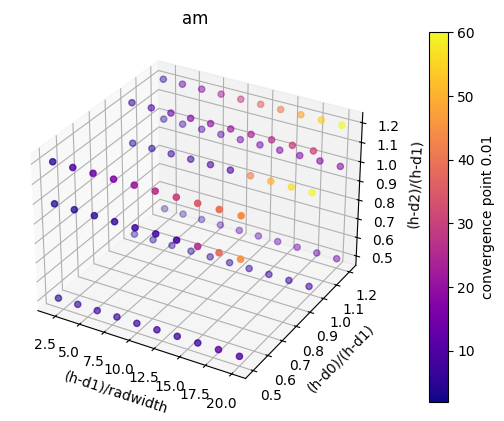

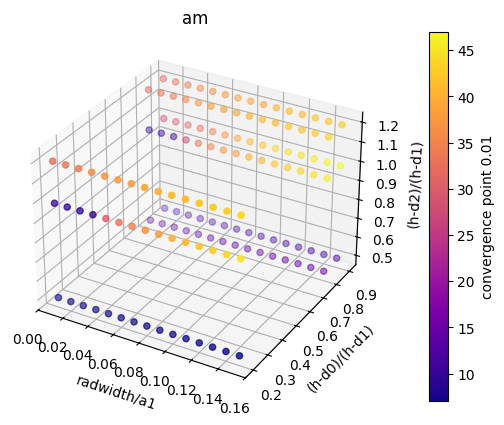

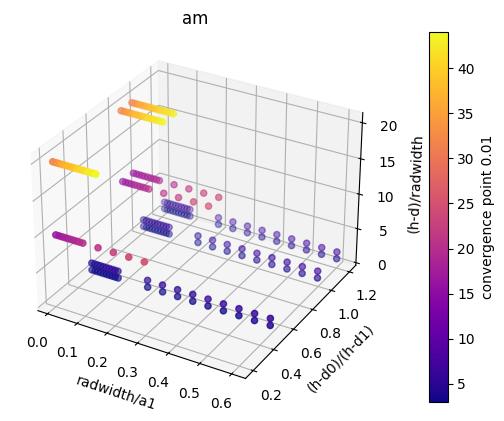

In [16]:
# Compare three of four identified influential dimensionless parameters

subset = restrict(all_data['(h-d)/radwidth'], rad_ratio, 0.15)

plot_hydros_against_3(subset, "am", 0.01,
                      wrap_m0(h_minus_d_over_radwidth),
                      wrap_m0(left_ratio), wrap_m0(right_ratio),
                      "(h-d1)/radwidth", "(h-d0)/(h-d1)", "(h-d2)/(h-d1)")

subset = restrict(all_data['rad ratio'], h_minus_d_over_radwidth, 20)

plot_hydros_against_3(subset, "am", 0.01,
                      wrap_m0(rad_ratio),
                      wrap_m0(left_ratio), wrap_m0(right_ratio),
                      "radwidth/a1", "(h-d0)/(h-d1)", "(h-d2)/(h-d1)")

subset = restrict(all_data['rad ratio'], right_ratio, 1.2)
plot_hydros_against_3(subset, "am", 0.01,
                      wrap_m0(rad_ratio),
                      wrap_m0(left_ratio), wrap_m0(h_minus_d_over_radwidth),
                      "radwidth/a1", "(h-d0)/(h-d1)", "(h-d)/radwidth")

# rad ratio doesn't really scale dramatically if a high (h-d)/(radwidth) isn't there to scale up the "base" value

In [ ]:
# Plot a single variable against the convergence point (Connect points with the same other variables with the same color)

variable_funcs = {"(h-d0)/(h-d1)" : left_ratio,
                  "(h-d2)/(h-d1)" : right_ratio,
                  "(h-d1)/radwidth" : h_minus_d_over_radwidth,
                  "radwidth/a1" : rad_ratio}

def subdivide_lst(data_lst, f, rtol = 0.01):
  group_dict = {}
  for data_dict in data_lst:
    val = f(data_dict)
    stored = False
    for key in group_dict.keys():
      if abs((val - key)/key) < rtol:
        group_dict[key].append(data_dict)
        stored = True
        break
    if not stored:
      group_dict[val] = [data_dict]
  return [group_dict[key] for key in group_dict.keys()] # turn dict into lst of lsts

def plot_wrt_one(data, hydro, error, scale = False, xlab = "Invalid Key", func_pack = None, show_labs = False):
  xfunc = variable_funcs[xlab]
  other_funcs = variable_funcs.copy()
  del other_funcs[xlab]

  key1, key2, key3 = other_funcs.keys()
  subdivision1 = subdivide_lst(data, other_funcs[key1])
  subdivision2 = [entry for sublist in subdivision1 for entry in subdivide_lst(sublist, other_funcs[key2])]
  subdivision3 = [entry for sublist in subdivision2 for entry in subdivide_lst(sublist, other_funcs[key3])]
  # subdivision3 should be a list of lists of data_dicts, with uniform values across the three keys

  line_count = len(subdivision3)
  for lst in subdivision3:
    lst.sort(key = xfunc)
  
  if func_pack is not None: # Plotting a prediction on the x-axis instead
    entry_func = func_pack["function"]
    xlab = func_pack["xlab"]
  else:
    entry_func = xfunc

  colors = [colormaps['viridis'](i/(line_count - 1)) for i in range(line_count)]
  
  fig, ax = plt.subplots()
  for idx, data_lst in enumerate(subdivision3):
    xs = [entry_func(data_dict) for data_dict in data_lst]
    ys = [data_dict[data_dict["m0s"][0]][f"convergence point {error:.2g} " + hydro] for data_dict in data_lst]
    vs = [other_funcs[key](data_lst[0]) for key in other_funcs.keys()]
    lab = key1 + f"= {vs[0]:.2g}, " + key2 + f" = {vs[1]:.2g}, " + key3 + f" = {vs[2]:.2g}"
    if scale:
      ys = scale_by(ys, ys[0])
    plt.plot(xs, ys, color = colors[idx], label = lab)
  

  ax.set_xlabel(xlab)
  if scale:
    ylab = "Ratio of NMK at convergence to that for 1st config"
  else:
    ylab = "NMK at convergence"
  if show_labs:
    ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
  ax.set_ylabel(ylab)
  ax.set_title(hydro + " convergence wrt " + xlab)
  plt.show()

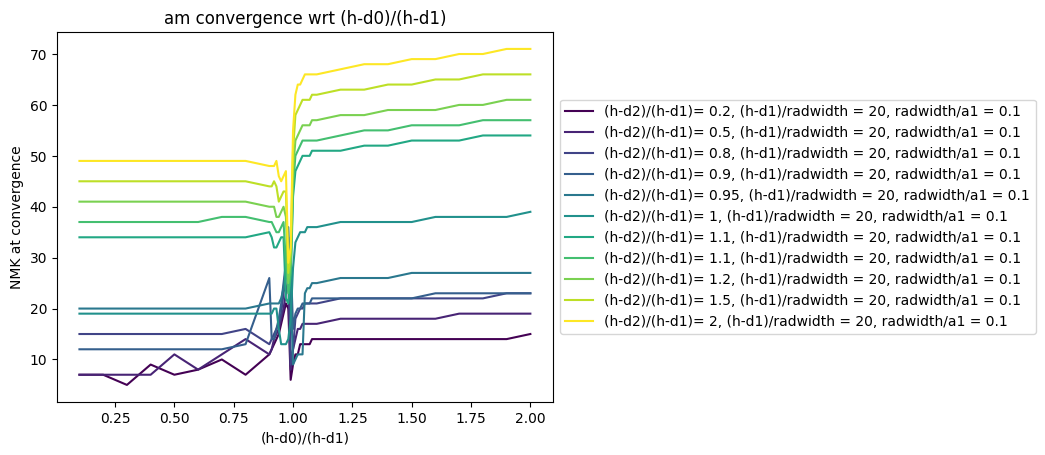

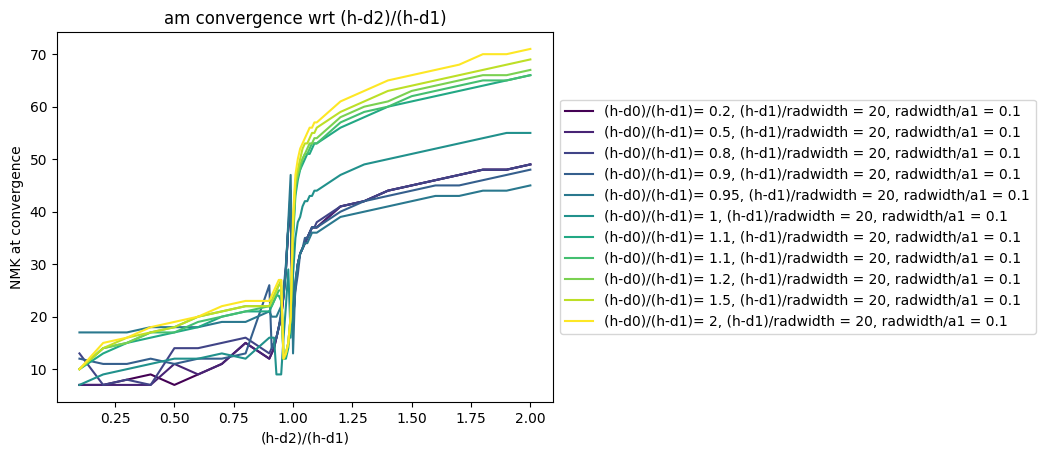

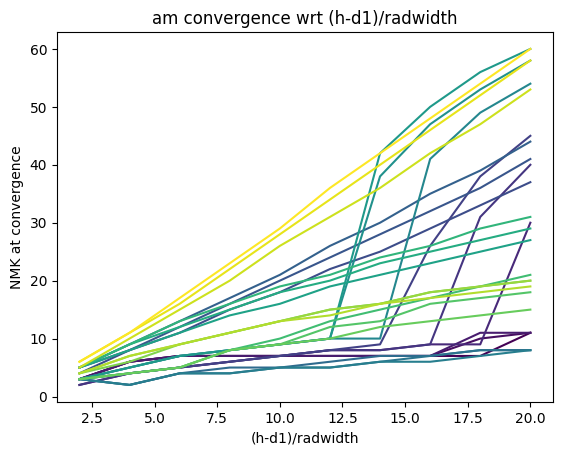

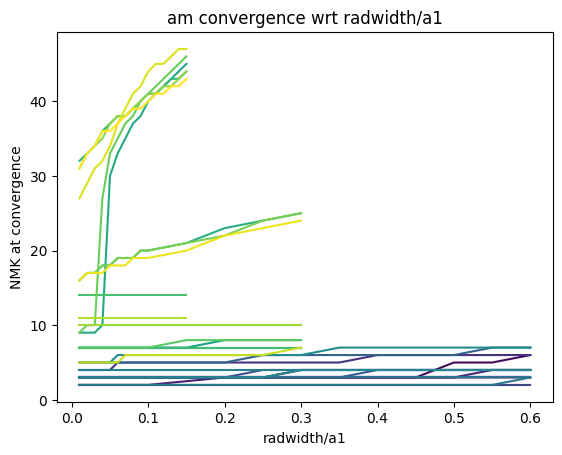

In [ ]:
# For added mass
selected_height_ratios = [0.2, 0.5, 0.8, 0.9, 0.95, 1, 1.05, 1.1, 1.2, 1.5, 2]
subsets = [restrict(all_data["height ratios"], right_ratio, val) for val in selected_height_ratios]
subset = [entry for sublst in subsets for entry in sublst]
plot_wrt_one(subset, "am", 0.01, xlab = "(h-d0)/(h-d1)", show_labs=True)

subsets = [restrict(all_data["height ratios"], left_ratio, val) for val in selected_height_ratios]
subset = [entry for sublst in subsets for entry in sublst]
plot_wrt_one(subset, "am", 0.01, xlab = "(h-d2)/(h-d1)", show_labs=True)

plot_wrt_one(all_data["(h-d)/radwidth"], "am", 0.01, xlab = "(h-d1)/radwidth")
plot_wrt_one(all_data["rad ratio"], "am", 0.01, xlab = "radwidth/a1")

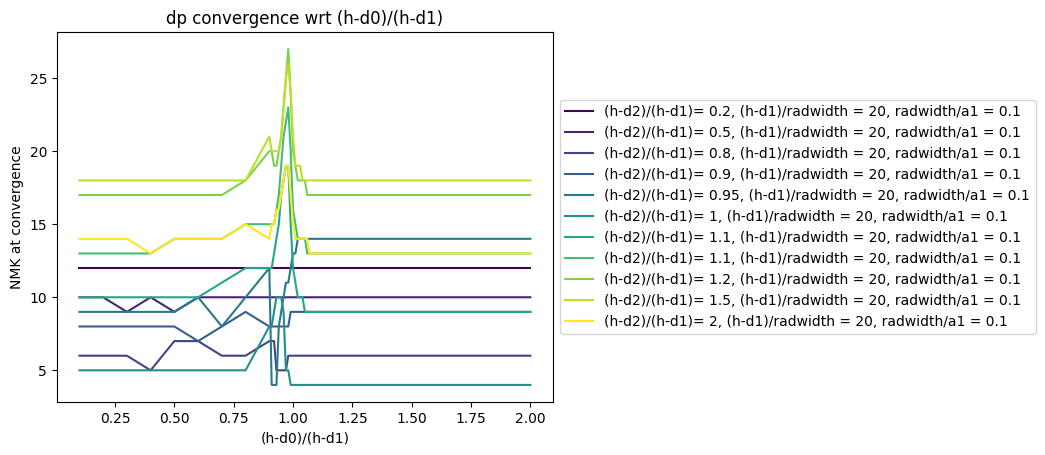

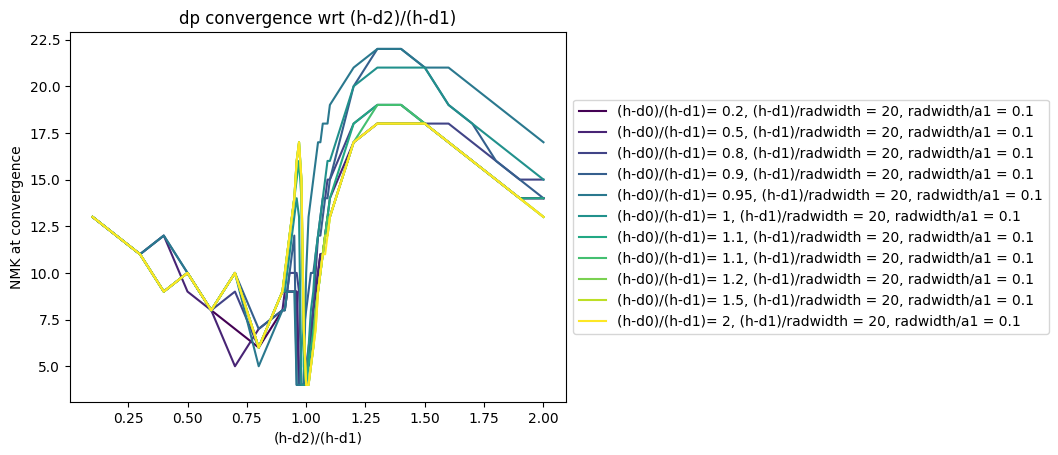

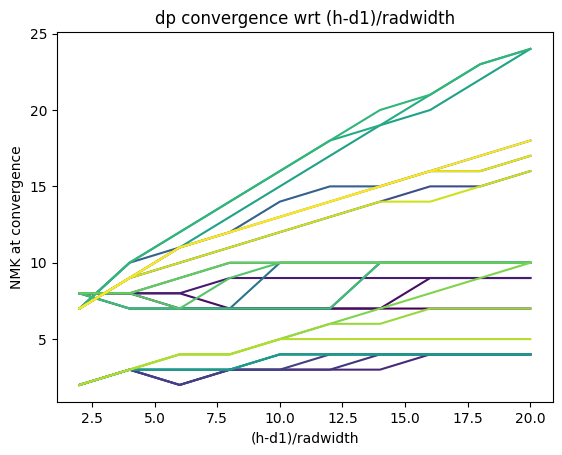

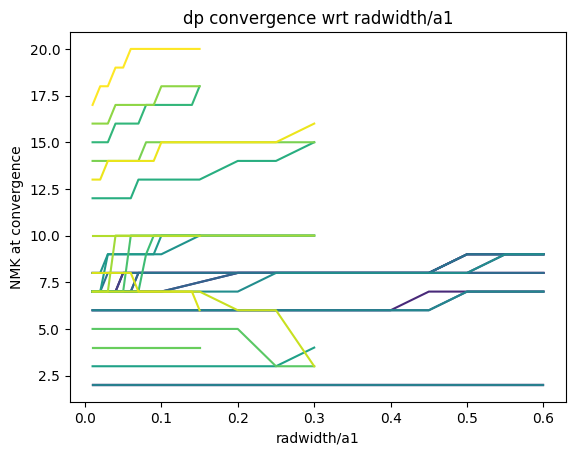

In [ ]:
# For damping
selected_height_ratios = [0.2, 0.5, 0.8, 0.9, 0.95, 1, 1.05, 1.1, 1.2, 1.5, 2]
subsets = [restrict(all_data["height ratios"], right_ratio, val) for val in selected_height_ratios]
subset = [entry for sublst in subsets for entry in sublst]
plot_wrt_one(subset, "dp", 0.01, xlab = "(h-d0)/(h-d1)", show_labs=True)

subsets = [restrict(all_data["height ratios"], left_ratio, val) for val in selected_height_ratios]
subset = [entry for sublst in subsets for entry in sublst]
plot_wrt_one(subset, "dp", 0.01, xlab = "(h-d2)/(h-d1)", show_labs=True)

plot_wrt_one(all_data["(h-d)/radwidth"], "dp", 0.01, xlab = "(h-d1)/radwidth")
plot_wrt_one(all_data["rad ratio"], "dp", 0.01, xlab = "radwidth/a1")